# Data Structures & Algorithms: Trees, Binary Search Trees and Heaps

> **Who is this for?** Beginners who are comfortable with Python classes and recursion and want to understand hierarchical data structures from the inside, and university students preparing for DSA exams or coding interviews.
>
> **What you will learn**
> - Tree vocabulary (root, parent, leaf, degree, depth, height, level) and the kinds of binary trees: **full**, **complete** and **perfect**, plus the array representation.
> - All four traversals (**preorder, inorder, postorder, level order**), each recursive *and* iterative, with pictures.
> - Classic tree problems: height, diameter, lowest common ancestor, left/right/top views, path sum, symmetric tree, serialise/deserialise.
> - **Binary search trees (BSTs):** search, insert, the three delete cases, validation, k-th smallest, inorder successor, and why a BST can degenerate into a linked list (measured experimentally).
> - **Balanced trees:** AVL rotations (LL, RR, LR, RL) with a working AVL insert, red-black trees conceptually, and B-trees.
> - **Heaps:** sift-up/sift-down, O(n) heapify (with the proof), heap sort, a priority-queue class, Python's `heapq`, and four heap interview problems.
>
> **Prerequisites**
> - [Python basics](../../01_Python/01_basic.ipynb) (classes, lists, dictionaries).
> - Recursion and Big-O: [01 · Complexity Analysis and Recursion](01_complexity_analysis_and_recursion.ipynb).
> - Stacks and queues: [05 · Linked Lists, Stacks and Queues](05_linked_lists_stacks_queues.ipynb) (iterative traversals use a stack, level order uses a queue).
>
> **Time needed:** about 4 hours (reading + running + practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, NumPy, pandas, matplotlib, networkx.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*. It is not required for the rest of the course, but it is recommended for BS/MS AI students and for interview preparation.

## Explained simply

A **tree** is a way of organising things in levels, where every item has exactly one "boss" above it, like a family tree or the folders on your computer. A **binary search tree** keeps numbers in order so you can find one by asking "smaller or bigger?" again and again, just like guessing a number between 1 and 100 in about 7 questions instead of 100. If you insert numbers in a bad order the tree turns into one long chain and becomes slow, so **balanced trees** (AVL, red-black) automatically tidy themselves up. A **heap** is a special tree that always keeps the smallest (or largest) item on top, like a hospital emergency room that always treats the most urgent patient next. Trees and heaps are behind databases, file systems, decision-tree models in machine learning and "find the top 5 results" in search engines.

**Tiny example.** Put 50, 30, 70, 20, 40 into a binary search tree. 50 sits at the top; 30 is smaller, so it goes left; 70 is bigger, so it goes right; 20 goes left of 30; 40 goes right of 30. To find 40 you check only 50 → 30 → 40: three looks instead of scanning all five numbers. In a heap of patients with urgency 3, 1, 5, the patient with urgency 1 is always on top and is treated first.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Tree | items arranged in levels, each with one parent | folders on a computer, company org charts, decision-tree ML models |
| Binary search tree | "smaller goes left, bigger goes right", so searching is like a guessing game | sorted indexes, autocomplete of ordered data, database indexes (B+ trees) |
| Heap | always gives you the smallest (or largest) item instantly | emergency-room triage, task schedulers, top-k search results in RAG |

## Table of contents
1. [Setup and a tree-drawing helper](#setup)
2. [Tree terminology](#terminology)
3. [Binary trees: full, complete, perfect; array representation](#binary)
4. [Traversals](#traversals)
5. [Classic tree problems](#problems)
6. [Binary search trees](#bst)
7. [Balanced trees: AVL, red-black, B-trees](#balanced)
8. [Heaps and priority queues](#heaps)
9. [Heap problems](#heap-problems)
10. [Complexity summary](#summary)
11. [How this connects to modern AI](#modern-ai)
12. [Recap, practice problems, further reading](#recap)

<a id="setup"></a>
## 1. Setup and a tree-drawing helper

> **In plain English:** we load our tools and write a small helper that draws any tree so we can see what the code does.

Trees are much easier to understand when you can see them. `draw_tree` places every node at x = its position in an inorder walk and y = −depth, then lets networkx draw the circles and lines. (No Graphviz needed.)

networkx 3.7 | pandas 2.3.3


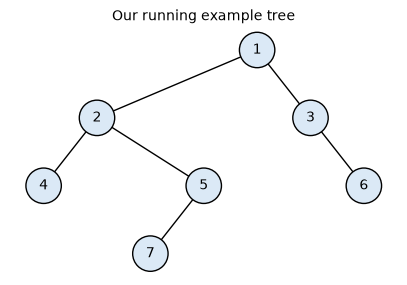

In [1]:
import random                                   # random test data
import math                                     # log2 and friends
import time                                     # simple timings
import itertools                                # counters for tie-breaking
import statistics                               # median, for checking our running median
from collections import deque, Counter          # queue for level order, frequency counts
import heapq                                    # Python's built-in binary heap
import bisect                                   # sorted-list helpers for checking BST answers

import numpy as np                              # numeric arrays
import pandas as pd                             # trace tables
import matplotlib.pyplot as plt                 # plots
import networkx as nx                           # drawing trees + reference algorithms

random.seed(42)
np.random.seed(42)
print("networkx", nx.__version__, "| pandas", pd.__version__)


class TreeNode:
    '''A binary-tree node. We call the stored key `val` everywhere in this notebook.'''
    def __init__(self, val, left=None, right=None):
        self.val = val                          # the key / data
        self.left = left                        # left child (or None)
        self.right = right                      # right child (or None)

    def __repr__(self):
        return f"TreeNode({self.val})"


def tree_positions(root):
    '''x = inorder index, y = -depth. Works for any binary tree.'''
    pos, counter = {}, [0]
    def walk(node, depth):
        if node is None:
            return
        walk(node.left, depth + 1)
        pos[node] = (counter[0], -depth)        # inorder: left subtree, node, right subtree
        counter[0] += 1
        walk(node.right, depth + 1)
    walk(root, 0)
    return pos


def draw_tree(root, ax, title="", colors=None, labels=None, node_size=650, font_size=10):
    '''Draw a binary tree. colors / labels: optional dicts keyed by node value.'''
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    if root is None:
        ax.text(0.5, 0.5, "(empty tree)", ha="center", transform=ax.transAxes)
        return
    pos = tree_positions(root)
    G = nx.DiGraph()
    for node in pos:
        G.add_node(node)
        for child in (node.left, node.right):
            if child is not None:
                G.add_edge(node, child)
    lab = {n: (labels.get(n.val, str(n.val)) if labels else str(n.val)) for n in G}
    col = [(colors.get(n.val, "#dbe9f6") if colors else "#dbe9f6") for n in G]
    nx.draw_networkx(G, pos, ax=ax, labels=lab, node_color=col, node_size=node_size,
                     edgecolors="black", arrows=False, font_size=font_size)


def from_level_order(values):
    '''Build a tree from a LeetCode-style level-order list, None = missing child.'''
    if not values or values[0] is None:
        return None
    it = iter(values)
    root = TreeNode(next(it))
    queue = deque([root])
    while queue:
        node = queue.popleft()
        for side in ("left", "right"):
            try:
                v = next(it)
            except StopIteration:
                return root
            if v is not None:
                child = TreeNode(v)
                setattr(node, side, child)
                queue.append(child)
    return root


def random_binary_tree(n, rng, values=None):
    '''Random tree shape with n nodes; values are distinct (preorder numbering unless given).'''
    values = iter(values if values is not None else range(1, n + 1))
    def make(size):
        if size == 0:
            return None
        left_size = rng.randint(0, size - 1)
        node = TreeNode(next(values))
        node.left = make(left_size)
        node.right = make(size - 1 - left_size)
        return node
    return make(n)


def to_networkx(root):
    '''Directed graph parent -> child (left child added first), nodes = values.'''
    G = nx.DiGraph()
    stack = [root] if root else []
    while stack:
        node = stack.pop()
        G.add_node(node.val)
        for child in (node.left, node.right):
            if child is not None:
                G.add_edge(node.val, child.val)
                stack.append(child)
    return G


example = from_level_order([1, 2, 3, 4, 5, None, 6, None, None, 7])
fig, ax = plt.subplots(figsize=(5, 3.2))
draw_tree(example, ax, "Our running example tree")
plt.show()

<a id="terminology"></a>
## 2. Tree terminology

> **In plain English:** the words people use to talk about trees: who is the root, who is a leaf, how deep or high a node is.

### 2.1 Intuition

A company organisation chart, a family tree, folders on your computer, the table of contents of a book: all are **trees**. There is one top item, and every other item has exactly one "boss" above it.

### 2.2 Definitions

- A **tree** is a connected, acyclic collection of **nodes** joined by **edges**. A tree with n nodes has exactly **n − 1 edges**.
- In a **rooted tree**, one node is the **root**. Every other node has exactly one **parent**; the nodes directly below a node are its **children**; nodes with the same parent are **siblings**.
- A **leaf** (external node) has no children; an **internal node** has at least one child.
- The **degree** of a node is its number of children; the degree of a tree is the maximum node degree.
- **Ancestors** of a node are the nodes on the path from it up to the root; **descendants** are the nodes below it. A **subtree** is a node together with all its descendants.
- The **depth** of a node is the number of edges from the root to it (the root has depth 0). The **level** of a node is usually its depth (some books start counting levels at 1).
- The **height** of a node is the number of edges on the *longest* downward path from it to a leaf (a leaf has height 0). The height of a tree is the height of its root; by convention the empty tree has height −1.

⚠️ **Common mistake:** some textbooks measure height and depth in **nodes** instead of edges (so a single node has height 1). Both conventions are used in exams; always state which one you use. This notebook counts **edges**.

Worked example:

```
              A                depth 0 (level 0)
           /  |  \
          B   C   D            depth 1
         / \      |
        E   F     G            depth 2
                 / \
                H   I          depth 3
```

| node | parent | children | degree | depth | height | leaf? |
|---|---|---|---|---|---|---|
| A | – | B, C, D | 3 | 0 | 3 | no |
| B | A | E, F | 2 | 1 | 1 | no |
| C | A | – | 0 | 1 | 0 | yes |
| D | A | G | 1 | 1 | 2 | no |
| G | D | H, I | 2 | 2 | 1 | no |
| E, F, H, I | ... | – | 0 | 2 or 3 | 0 | yes |

So the tree has height 3, degree 3 and 5 leaves (E, F, C, H, I). Let us compute the same table with code.

,parent,children,degree,depth,height,leaf?
node,,,,,,
A,-,"B, C, D",3,0,3,False
B,A,"E, F",2,1,1,False
E,B,-,0,2,0,True
F,B,-,0,2,0,True
C,A,-,0,1,0,True
D,A,G,1,1,2,False
G,D,"H, I",2,2,1,False
H,G,-,0,3,0,True
I,G,-,0,3,0,True


tree height: 3 | tree degree: 3 | leaves: ['E', 'F', 'C', 'H', 'I'] | nodes: 9 | edges: 8
depths and heights match networkx; edges = nodes - 1


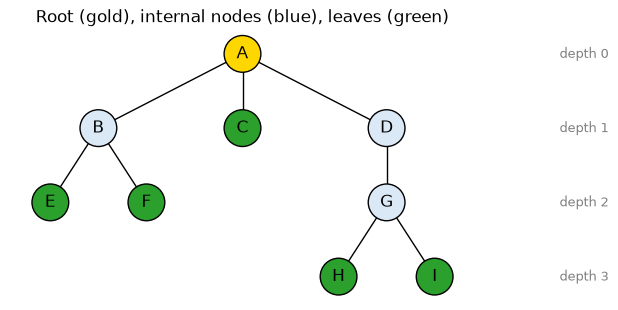

In [2]:
class GeneralTreeNode:
    '''A node of a general (n-ary) tree: any number of children.'''
    def __init__(self, name, children=()):
        self.name = name
        self.children = list(children)


root = GeneralTreeNode("A", [
    GeneralTreeNode("B", [GeneralTreeNode("E"), GeneralTreeNode("F")]),
    GeneralTreeNode("C"),
    GeneralTreeNode("D", [GeneralTreeNode("G", [GeneralTreeNode("H"), GeneralTreeNode("I")])]),
])


def node_height(node):                            # longest downward path, in edges
    return 0 if not node.children else 1 + max(node_height(c) for c in node.children)


def describe(root):
    rows = []
    def visit(node, parent, depth):
        rows.append({"node": node.name, "parent": parent.name if parent else "-",
                     "children": ", ".join(c.name for c in node.children) or "-",
                     "degree": len(node.children), "depth": depth, "height": node_height(node),
                     "leaf?": not node.children})
        for c in node.children:
            visit(c, node, depth + 1)
    visit(root, None, 0)
    return pd.DataFrame(rows).set_index("node")


table = describe(root)
display(table)
print("tree height:", table.loc["A", "height"], "| tree degree:", table["degree"].max(),
      "| leaves:", list(table.index[table["leaf?"]]), "| nodes:", len(table), "| edges:", (table["parent"] != "-").sum())

# cross-check depths and heights with networkx
G = nx.DiGraph()
stack = [root]
while stack:
    n = stack.pop()
    for c in n.children:
        G.add_edge(n.name, c.name); stack.append(c)
depths = nx.shortest_path_length(G, "A")                        # BFS distances from the root
assert all(depths[v] == table.loc[v, "depth"] for v in table.index)
assert all(max(depths[d] for d in nx.descendants(G, v) | {v}) - depths[v] == table.loc[v, "height"] for v in table.index)
assert G.number_of_edges() == G.number_of_nodes() - 1 and nx.is_tree(G.to_undirected())
print("depths and heights match networkx; edges = nodes - 1")


def general_positions(root):
    pos, next_x = {}, [0]
    def place(node, depth):
        if not node.children:
            pos[node.name] = (next_x[0], -depth); next_x[0] += 1
        else:
            for c in node.children:
                place(c, depth + 1)
            xs = [pos[c.name][0] for c in node.children]
            pos[node.name] = ((min(xs) + max(xs)) / 2, -depth)    # parent centred over its children
    place(root, 0)
    return pos

fig, ax = plt.subplots(figsize=(6, 3.5))
colours = ["tab:green" if table.loc[v, "leaf?"] else ("gold" if v == "A" else "#dbe9f6") for v in G]
nx.draw_networkx(G, general_positions(root), ax=ax, node_color=colours, node_size=700, edgecolors="black", arrows=False)
for d in range(4):
    ax.text(5.3, -d, f"depth {d}", va="center", fontsize=9, color="gray")
ax.set_title("Root (gold), internal nodes (blue), leaves (green)"); ax.axis("off"); plt.show()

**What just happened?** The code reproduces the hand-made table: height 3, degree 3, leaves E, F, C, H, I, and 9 nodes with 8 edges (n − 1). networkx agrees on every depth and height.

<a id="binary"></a>
## 3. Binary trees

> **In plain English:** a binary tree gives every node at most two children, and some shapes are so regular they fit neatly in a list.

A **binary tree** is a rooted tree where every node has **at most two** children, called the **left** and **right** child (the order matters: a node with only a left child is a different tree from one with only a right child).

| Kind | Definition | Example property |
|---|---|---|
| **Full** (proper, strict) | every node has **0 or 2** children | leaves = internal nodes + 1 |
| **Perfect** | full, and **all leaves at the same depth** | height h ⇒ exactly 2^(h+1) − 1 nodes |
| **Complete** | every level is full **except possibly the last**, which is filled **from the left** | n nodes ⇒ height ⌊log₂ n⌋; stored in an array with no gaps |
| **Balanced** (height-balanced) | for every node, left and right subtree heights differ by ≤ 1 | height O(log n) |
| **Degenerate** (skewed) | every internal node has one child | it is really a linked list; height n − 1 |

⚠️ **Common mistake (terminology clash):** CLRS calls a *perfect* tree a "complete binary tree", and some older texts call a *full* tree "complete". The definitions above (full / complete / perfect) are the ones used by most current courses, GeeksforGeeks and interviewers; quote the definition when you answer.

Useful facts:
- Level d holds at most 2^d nodes; a binary tree of height h has at most 2^(h+1) − 1 nodes, so **h ≥ ⌊log₂ n⌋**.
- Every perfect tree is full and complete; full and complete are independent of each other.

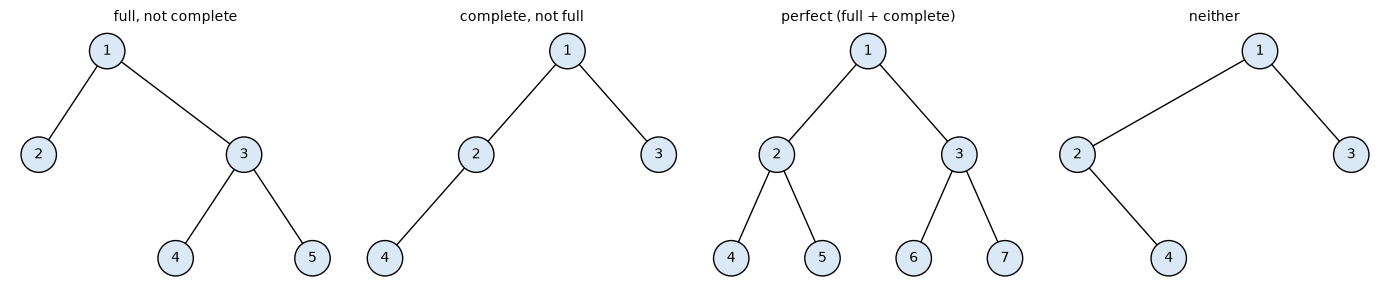

,nodes,height,full,complete,perfect
tree,,,,,
"full, not complete",5,2,True,False,False
"complete, not full",4,2,False,True,False
perfect (full + complete),7,2,True,True,True
neither,4,2,False,False,False


leaves = internal + 1 holds for 300 random full binary trees


In [3]:
def count_nodes(node):
    return 0 if node is None else 1 + count_nodes(node.left) + count_nodes(node.right)

def height(node):                                  # edges; empty tree = -1
    return -1 if node is None else 1 + max(height(node.left), height(node.right))

def is_full(node):
    if node is None:
        return True
    if (node.left is None) != (node.right is None):    # exactly one child -> not full
        return False
    return is_full(node.left) and is_full(node.right)

def is_complete(root):
    '''Level-order scan: once we meet a missing child, no real node may follow.'''
    queue, seen_gap = deque([root]), False
    while queue:
        node = queue.popleft()
        if node is None:
            seen_gap = True
        else:
            if seen_gap:
                return False
            queue.append(node.left); queue.append(node.right)
    return True

def is_perfect(root):
    return count_nodes(root) == 2 ** (height(root) + 1) - 1

shapes = {
    "full, not complete":       from_level_order([1, 2, 3, None, None, 4, 5]),
    "complete, not full":       from_level_order([1, 2, 3, 4]),
    "perfect (full + complete)": from_level_order([1, 2, 3, 4, 5, 6, 7]),
    "neither":                  from_level_order([1, 2, 3, None, 4]),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
rows = []
for ax, (name, t) in zip(axes, shapes.items()):
    draw_tree(t, ax, name)
    rows.append({"tree": name, "nodes": count_nodes(t), "height": height(t), "full": is_full(t),
                 "complete": is_complete(t), "perfect": is_perfect(t)})
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("tree"))

# Property check on random trees: in a FULL binary tree, leaves = internal + 1.
rng = random.Random(0)
def random_full_tree(internal):
    if internal == 0:
        return TreeNode(0)
    k = rng.randint(0, internal - 1)
    return TreeNode(0, random_full_tree(k), random_full_tree(internal - 1 - k))
def leaves(node):
    return 0 if node is None else 1 if node.left is None and node.right is None else leaves(node.left) + leaves(node.right)
for _ in range(300):
    i = rng.randint(0, 40); t = random_full_tree(i)
    assert is_full(t) and leaves(t) == i + 1
print("leaves = internal + 1 holds for 300 random full binary trees")

**What just happened?** The four checkers agree with the definitions: the tree `[1, 2, 3, None, None, 4, 5]` is full but not complete (its last level is not filled from the left); `[1, 2, 3, 4]` is complete but not full (node 2 has one child); the 7-node tree is perfect, hence also full and complete.

### 3.1 Array representation

A **complete** binary tree can be stored in a plain array **without any pointers**, level by level from left to right (0-based indices):

| relation | index |
|---|---|
| left child of i | 2i + 1 |
| right child of i | 2i + 2 |
| parent of i | ⌊(i − 1) / 2⌋ |

```
            10 (0)
          /        \
      20 (1)       30 (2)
      /   \        /
  40 (3) 50 (4) 60 (5)          array: [10, 20, 30, 40, 50, 60]
```

This is exactly how **heaps** are stored (section 8). For a tree that is *not* complete the array needs `None` gaps, and a degenerate tree of height h would need 2^(h+1) − 1 slots for only h + 1 nodes.

In [4]:
def tree_to_array(root):
    '''Store a binary tree in an array using index rules 2i+1 / 2i+2 (None = empty slot).'''
    arr = []
    def place(node, i):
        if node is None:
            return
        if i >= len(arr):
            arr.extend([None] * (i + 1 - len(arr)))
        arr[i] = node.val
        place(node.left, 2 * i + 1)
        place(node.right, 2 * i + 2)
    place(root, 0)
    return arr

def array_to_tree(arr, i=0):
    if i >= len(arr) or arr[i] is None:
        return None
    return TreeNode(arr[i], array_to_tree(arr, 2 * i + 1), array_to_tree(arr, 2 * i + 2))

def same_tree(a, b):
    if a is None or b is None:
        return a is b
    return a.val == b.val and same_tree(a.left, b.left) and same_tree(a.right, b.right)

complete = from_level_order([10, 20, 30, 40, 50, 60])
print("complete tree   ->", tree_to_array(complete))
print("children of index 1 (value 20):", [tree_to_array(complete)[j] for j in (2 * 1 + 1, 2 * 1 + 2)], "| parent of index 5:", (5 - 1) // 2)
print("our example tree ->", tree_to_array(example))
skewed = from_level_order([1, None, 2, None, 3, None, 4])
print("right-skewed 4 nodes needs", len(tree_to_array(skewed)), "slots:", tree_to_array(skewed))

rng = random.Random(1)
for _ in range(300):
    t = random_binary_tree(rng.randint(0, 12), rng)
    assert same_tree(array_to_tree(tree_to_array(t)), t)
print("tree -> array -> tree round trip works on 300 random trees")

complete tree   -> [10, 20, 30, 40, 50, 60]
children of index 1 (value 20): [40, 50] | parent of index 5: 2
our example tree -> [1, 2, 3, 4, 5, None, 6, None, None, 7]
right-skewed 4 nodes needs 15 slots: [1, None, 2, None, None, None, 3, None, None, None, None, None, None, None, 4]
tree -> array -> tree round trip works on 300 random trees


**What just happened?** The complete tree fits in 6 slots with no gaps, and index arithmetic finds children (indices 3 and 4 hold 40 and 50) and parents without pointers. Our 7-node example tree needs 10 slots because of the gaps, and the right-skewed tree with 4 nodes needs 15 slots (2⁴ − 1), which is why arrays are only used for complete trees.

<a id="traversals"></a>
## 4. Traversals

> **In plain English:** a traversal is a fixed route that visits every node exactly once; the route you choose decides the order you see them in.

A **traversal** visits every node exactly once. For binary trees there are four standard orders:

| Traversal | Order | Running example result | Typical use |
|---|---|---|---|
| **Preorder** | node, left, right | 1 2 4 5 7 3 6 | copy/serialise a tree, prefix expressions |
| **Inorder** | left, node, right | 4 2 7 5 1 3 6 | BST → sorted order |
| **Postorder** | left, right, node | 4 7 5 2 6 3 1 | delete/free a tree, evaluate expression trees, compute heights |
| **Level order** (BFS) | level by level, left to right | 1 2 3 4 5 6 7 | shortest paths in trees, views, serialisation |

The first three are **depth-first** (DFS). Recursive versions are three-liners; iterative versions replace the call stack by an explicit stack (useful when the tree is deeper than Python's recursion limit). Level order uses a **queue**.

In [5]:
# ---------- recursive ----------
def preorder(node):
    return [] if node is None else [node.val] + preorder(node.left) + preorder(node.right)

def inorder(node):
    return [] if node is None else inorder(node.left) + [node.val] + inorder(node.right)

def postorder(node):
    return [] if node is None else postorder(node.left) + postorder(node.right) + [node.val]

# ---------- iterative ----------
def preorder_iter(root):
    out, stack = [], [root] if root else []
    while stack:
        node = stack.pop()
        out.append(node.val)                     # visit when popped
        if node.right: stack.append(node.right)  # push right FIRST so left is popped first
        if node.left: stack.append(node.left)
    return out

def inorder_iter(root):
    out, stack, node = [], [], root
    while stack or node:
        while node:                              # go as far left as possible, remembering the path
            stack.append(node)
            node = node.left
        node = stack.pop()                       # leftmost unvisited node
        out.append(node.val)
        node = node.right                        # then do the same for its right subtree
    return out

def postorder_iter(root):
    '''Postorder = reverse of a (node, right, left) preorder.'''
    out, stack = [], [root] if root else []
    while stack:
        node = stack.pop()
        out.append(node.val)
        if node.left: stack.append(node.left)    # left pushed first -> right popped first
        if node.right: stack.append(node.right)
    return out[::-1]

def level_order(root):
    out, queue = [], deque([root] if root else [])
    while queue:
        node = queue.popleft()
        out.append(node.val)
        if node.left: queue.append(node.left)
        if node.right: queue.append(node.right)
    return out

def levels(root):
    '''Level order grouped by level: [[level 0], [level 1], ...].'''
    result, queue = [], deque([root] if root else [])
    while queue:
        result.append([])
        for _ in range(len(queue)):              # exactly the nodes of the current level
            node = queue.popleft()
            result[-1].append(node.val)
            if node.left: queue.append(node.left)
            if node.right: queue.append(node.right)
    return result

for name, f, g in [("preorder", preorder, preorder_iter), ("inorder", inorder, inorder_iter), ("postorder", postorder, postorder_iter)]:
    print(f"{name:10} recursive {f(example)} | iterative {g(example)}")
print("level order", level_order(example), "| by level:", levels(example))

preorder   recursive [1, 2, 4, 5, 7, 3, 6] | iterative [1, 2, 4, 5, 7, 3, 6]
inorder    recursive [4, 2, 7, 5, 1, 3, 6] | iterative [4, 2, 7, 5, 1, 3, 6]
postorder  recursive [4, 7, 5, 2, 6, 3, 1] | iterative [4, 7, 5, 2, 6, 3, 1]
level order [1, 2, 3, 4, 5, 6, 7] | by level: [[1], [2, 3], [4, 5, 6], [7]]


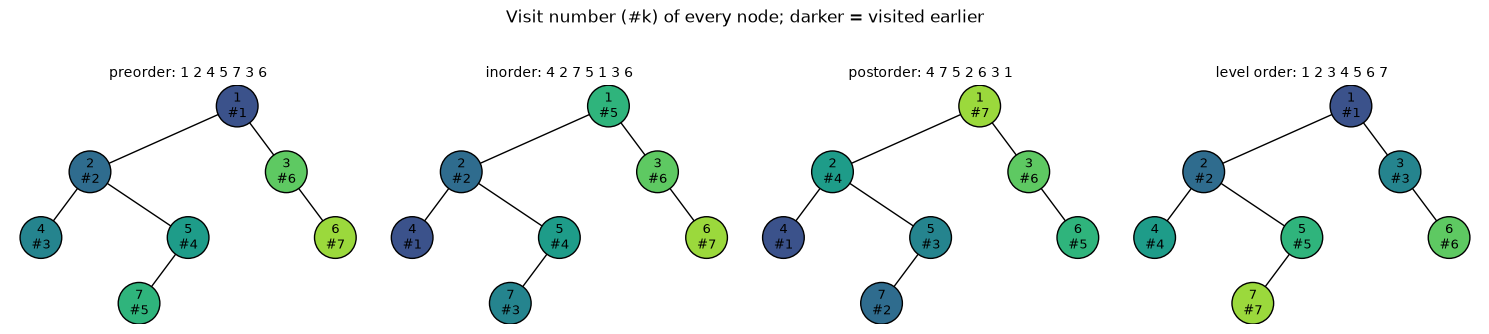

all traversals agree (recursive vs iterative vs networkx) on 500 random trees


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (name, f) in zip(axes, [("preorder", preorder), ("inorder", inorder), ("postorder", postorder), ("level order", level_order)]):
    order = f(example)
    labels = {v: f"{v}\n#{order.index(v) + 1}" for v in order}        # value + visit number
    cmap = plt.cm.viridis
    colors = {v: cmap(0.25 + 0.7 * order.index(v) / len(order)) for v in order}
    draw_tree(example, ax, f"{name}: " + " ".join(map(str, order)), colors=colors, labels=labels, node_size=900, font_size=9)
plt.suptitle("Visit number (#k) of every node; darker = visited earlier", y=1.03); plt.tight_layout(); plt.show()

# Randomised check: iterative == recursive, and pre/post/level order also match networkx's DFS/BFS
rng = random.Random(2)
for _ in range(500):
    t = random_binary_tree(rng.randint(1, 60), rng)
    assert preorder(t) == preorder_iter(t) and inorder(t) == inorder_iter(t) and postorder(t) == postorder_iter(t)
    G = to_networkx(t)
    assert preorder(t) == list(nx.dfs_preorder_nodes(G, t.val))
    assert postorder(t) == list(nx.dfs_postorder_nodes(G, t.val))
    assert level_order(t) == [t.val] + [v for _, v in nx.bfs_edges(G, t.val)]
    assert sum(levels(t), []) == level_order(t)
print("all traversals agree (recursive vs iterative vs networkx) on 500 random trees")

**What just happened?** The four pictures label each node with its visit number. Every traversal is **O(n) time** (each node visited once). Space is **O(h)** for the DFS orders (the stack holds one path, h = height: O(log n) for balanced trees, O(n) for skewed ones) and **O(w)** for level order (w = maximum width, up to about n/2 for a perfect tree). networkx's generic graph DFS/BFS (children inserted left first) produced exactly the same pre-, post- and level orders.

🎓 **Exam / interview tip:** a binary tree is uniquely determined by its **inorder plus preorder** (or inorder plus postorder) traversal when keys are distinct, but **not** by preorder plus postorder alone (a node with one child could have it on either side). Rebuilding from preorder + inorder is practice problem 4.

<a id="problems"></a>
## 5. Classic tree problems

> **In plain English:** most tree puzzles are solved by asking each subtree a small question and combining the answers at the node.

Most tree problems follow one pattern: **ask each subtree for some information (recursively), then combine at the node** (a postorder pattern). Height is the simplest example: `height(node) = 1 + max(height(left), height(right))`.

### 5.1 Height and diameter

The **diameter** is the number of edges on the longest path between *any* two nodes. The longest path through a node uses `height(left) + height(right) + 2` edges, so one postorder pass computing heights can track the best diameter: O(n), instead of O(n²) for "compute heights again at every node".

In [7]:
def diameter(root):
    best = 0
    def h(node):                                 # returns the height, updates `best` on the way
        nonlocal best
        if node is None:
            return -1
        hl, hr = h(node.left), h(node.right)
        best = max(best, hl + hr + 2)            # longest path that bends at this node
        return 1 + max(hl, hr)
    h(root)
    return best

print("example tree: height =", height(example), "| diameter =", diameter(example), "(path 7-5-2-1-3-6)")
rng = random.Random(3)
for _ in range(300):
    t = random_binary_tree(rng.randint(1, 80), rng)
    G = to_networkx(t).to_undirected()
    assert diameter(t) == (nx.diameter(G) if len(G) > 1 else 0)          # networkx: max eccentricity
    assert height(t) == max(nx.shortest_path_length(to_networkx(t), t.val).values())
print("height and diameter match networkx on 300 random trees")

example tree: height = 3 | diameter = 5 (path 7-5-2-1-3-6)


height and diameter match networkx on 300 random trees


### 5.2 Lowest common ancestor (LCA)

The **LCA** of nodes p and q is the deepest node that has both as descendants (a node counts as its own descendant). Recursive idea: search both subtrees; if p and q are found in *different* subtrees, the current node is the LCA; if both are in one subtree, the answer is there. O(n) time, O(h) space.

In [8]:
def lca(node, p, q):
    if node is None or node.val in (p, q):       # found one of them (or fell off the tree)
        return node
    left = lca(node.left, p, q)
    right = lca(node.right, p, q)
    if left and right:                           # p and q on different sides
        return node
    return left or right                         # both on one side (or neither)

print("LCA(4, 7) =", lca(example, 4, 7).val, "| LCA(7, 6) =", lca(example, 7, 6).val, "| LCA(5, 7) =", lca(example, 5, 7).val)

rng = random.Random(4)
for _ in range(200):
    n = rng.randint(1, 50); t = random_binary_tree(n, rng); G = to_networkx(t)
    for _ in range(5):
        p, q = rng.randint(1, n), rng.randint(1, n)
        assert lca(t, p, q).val == nx.lowest_common_ancestor(G, p, q)
print("LCA matches networkx.lowest_common_ancestor on 1000 random queries")

LCA(4, 7) = 2 | LCA(7, 6) = 1 | LCA(5, 7) = 5


LCA matches networkx.lowest_common_ancestor on 1000 random queries


**What just happened?** LCA(4, 7) = 2, LCA(7, 6) = 1 (they are in different subtrees of the root), and LCA(5, 7) = 5 (a node is an ancestor of itself). For a **BST** the LCA is even easier: walk down from the root until p and q fall on different sides (O(h)).

### 5.3 Left, right and top views

- **Left view:** the first node of every level (what you see standing to the left). **Right view:** the last node of every level.
- **Top view:** give the root horizontal distance hd = 0, a left child hd − 1, a right child hd + 1. Looking from above you see, for every hd, the **highest** node (smallest depth; ties broken by level-order position).

left view : [1, 2, 4, 7]
right view: [1, 3, 6, 7]
top view  : [4, 2, 1, 3, 6]


top view matches the brute-force definition on 500 random trees


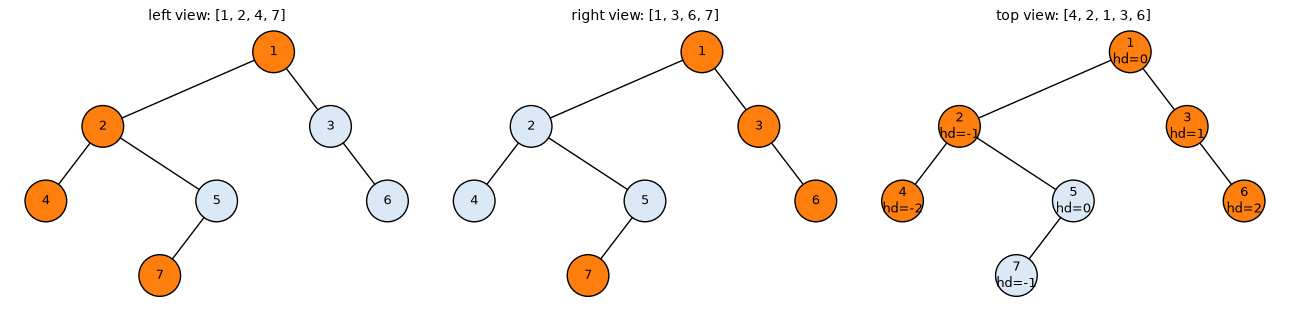

In [9]:
def left_view(root):
    return [lvl[0] for lvl in levels(root)]

def right_view(root):
    return [lvl[-1] for lvl in levels(root)]

def top_view(root):
    first_at = {}                                # hd -> value of the first node seen at that hd
    queue = deque([(root, 0)] if root else [])
    while queue:                                 # BFS guarantees the highest node is seen first
        node, hd = queue.popleft()
        first_at.setdefault(hd, node.val)
        if node.left: queue.append((node.left, hd - 1))
        if node.right: queue.append((node.right, hd + 1))
    return [first_at[hd] for hd in sorted(first_at)]

def top_view_brute(root):                        # collect (hd, depth, level-order index) for all nodes, take the minimum
    info, order = [], {v: i for i, v in enumerate(level_order(root))}
    def walk(node, hd, depth):
        if node:
            info.append((hd, depth, order[node.val], node.val))
            walk(node.left, hd - 1, depth + 1); walk(node.right, hd + 1, depth + 1)
    walk(root, 0, 0)
    best = {}
    for hd, depth, idx, val in info:
        if hd not in best or (depth, idx) < best[hd][:2]:
            best[hd] = (depth, idx, val)
    return [best[hd][2] for hd in sorted(best)]

print("left view :", left_view(example))
print("right view:", right_view(example))
print("top view  :", top_view(example))
rng = random.Random(5)
for _ in range(500):
    t = random_binary_tree(rng.randint(1, 40), rng)
    assert top_view(t) == top_view_brute(t)
print("top view matches the brute-force definition on 500 random trees")

hd = {}
def assign_hd(node, d):
    if node: hd[node.val] = d; assign_hd(node.left, d - 1); assign_hd(node.right, d + 1)
assign_hd(example, 0)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (name, view) in zip(axes, [("left view", left_view(example)), ("right view", right_view(example)), ("top view", top_view(example))]):
    labels = {v: f"{v}\nhd={hd[v]}" for v in hd} if name == "top view" else None
    draw_tree(example, ax, f"{name}: {view}", colors={v: "tab:orange" for v in view}, labels=labels, node_size=900, font_size=9)
plt.tight_layout(); plt.show()

**What just happened?** The left view is `[1, 2, 4, 7]`, the right view `[1, 3, 6, 7]` and the top view `[4, 2, 1, 3, 6]`. In the top view node 5 (hd = 0) is hidden under the root, and node 7 (hd = −1) is hidden under node 2, because those nodes are higher at the same horizontal distance. All views are O(n) BFS passes.

### 5.4 Path sum

**Problem:** is there a **root-to-leaf** path whose values add up to a target? Subtract the node's value from the target as you go down; at a leaf, check whether the remainder is 0. We also collect all such paths and check them against networkx's path enumeration.

In [10]:
def has_path_sum(node, target):
    if node is None:
        return False
    if node.left is None and node.right is None:  # leaf: did we use up the target exactly?
        return target == node.val
    rest = target - node.val
    return has_path_sum(node.left, rest) or has_path_sum(node.right, rest)

def paths_with_sum(root, target):
    result, path = [], []
    def dfs(node, remaining):
        if node is None:
            return
        path.append(node.val)                    # choose
        if node.left is None and node.right is None and remaining == node.val:
            result.append(list(path))
        dfs(node.left, remaining - node.val)     # explore
        dfs(node.right, remaining - node.val)
        path.pop()                               # un-choose (backtrack)
    dfs(root, target)
    return result

G_ex = to_networkx(example)
for leaf in [v for v in G_ex if G_ex.out_degree(v) == 0]:
    p = nx.shortest_path(G_ex, example.val, leaf)
    print("root-to-leaf path", p, "sum", sum(p))
for target in (15, 10, 8):
    print(f"has_path_sum({target}) -> {has_path_sum(example, target)}  paths: {paths_with_sum(example, target)}")

rng = random.Random(6)
for _ in range(300):
    n = rng.randint(1, 30)
    t = random_binary_tree(n, rng, values=rng.sample(range(-20, 40), n))
    G = to_networkx(t)
    leaves_ = [v for v in G if G.out_degree(v) == 0]
    all_paths = [p for leaf in leaves_ for p in nx.all_simple_paths(G, t.val, leaf)] if n > 1 else [[t.val]]
    target = sum(rng.choice(all_paths)) if rng.random() < 0.7 else rng.randint(-50, 100)
    expected = sorted(p for p in all_paths if sum(p) == target)
    assert sorted(paths_with_sum(t, target)) == expected and has_path_sum(t, target) == bool(expected)
print("path-sum functions match networkx path enumeration on 300 random trees")

root-to-leaf path [1, 3, 6] sum 10
root-to-leaf path [1, 2, 4] sum 7
root-to-leaf path [1, 2, 5, 7] sum 15
has_path_sum(15) -> True  paths: [[1, 2, 5, 7]]
has_path_sum(10) -> True  paths: [[1, 3, 6]]
has_path_sum(8) -> False  paths: []


path-sum functions match networkx path enumeration on 300 random trees


**What just happened?** The example's root-to-leaf paths are 1-2-4 (sum 7), 1-2-5-7 (sum 15) and 1-3-6 (sum 10). `has_path_sum(15)` finds the path `[1, 2, 5, 7]`, target 10 finds `[1, 3, 6]`, and target 8 has no root-to-leaf path (1-2-5 sums to 8 but ends at node 5, which is not a leaf). The `path.append` / `path.pop` pair is the **backtracking** pattern you will meet again in search and constraint satisfaction.

### 5.5 Symmetric tree

A tree is **symmetric** if it is a mirror image of itself around the root. Two subtrees `a` and `b` are mirrors if their roots are equal, `a.left` mirrors `b.right`, and `a.right` mirrors `b.left`.

In [11]:
def is_mirror(a, b):
    if a is None or b is None:
        return a is b                            # both missing -> mirror; one missing -> not
    return a.val == b.val and is_mirror(a.left, b.right) and is_mirror(a.right, b.left)

def is_symmetric(root):
    return root is None or is_mirror(root.left, root.right)

def is_symmetric_iter(root):                     # same idea with a queue of pairs
    queue = deque([(root.left, root.right)] if root else [])
    while queue:
        a, b = queue.popleft()
        if a is None and b is None:
            continue
        if a is None or b is None or a.val != b.val:
            return False
        queue.append((a.left, b.right)); queue.append((a.right, b.left))
    return True

def mirror_copy(node):
    return None if node is None else TreeNode(node.val, mirror_copy(node.right), mirror_copy(node.left))

sym = from_level_order([1, 2, 2, 3, 4, 4, 3])
asym = from_level_order([1, 2, 2, None, 3, None, 3])
print("[1,2,2,3,4,4,3] symmetric?", is_symmetric(sym), "| [1,2,2,None,3,None,3] symmetric?", is_symmetric(asym))

rng = random.Random(7)
for _ in range(500):
    half = random_binary_tree(rng.randint(0, 10), rng, values=[rng.randint(0, 2) for _ in range(10)])
    t = TreeNode(0, half, mirror_copy(half))                    # symmetric by construction
    if rng.random() < 0.5 and half is not None:
        half.val += 1                                            # break the symmetry (most of the time)
    expected = same_tree(t.left, mirror_copy(t.right))
    assert is_symmetric(t) == is_symmetric_iter(t) == expected
print("recursive and iterative symmetry checks agree with the mirror-copy definition on 500 trees")

[1,2,2,3,4,4,3] symmetric? True | [1,2,2,None,3,None,3] symmetric? False
recursive and iterative symmetry checks agree with the mirror-copy definition on 500 trees


### 5.6 Serialise and deserialise

**Serialisation** turns a tree into a string (to save it to disk or send it over a network); **deserialisation** rebuilds the identical tree. Writing a **preorder** walk with a marker `#` for every missing child is enough to rebuild the tree uniquely: read the values back in the same order, and a `#` means "no node here".

For the example tree: `1,2,4,#,#,5,7,#,#,#,3,#,6,#,#`.

In [12]:
def serialise(root):
    out = []
    def walk(node):
        if node is None:
            out.append("#"); return
        out.append(str(node.val))                # preorder: node, left, right
        walk(node.left); walk(node.right)
    walk(root)
    return ",".join(out)

def deserialise(data):
    tokens = iter(data.split(","))
    def build():
        tok = next(tokens)
        if tok == "#":
            return None
        node = TreeNode(int(tok))
        node.left = build()                      # consume tokens in the same preorder
        node.right = build()
        return node
    return build()

s = serialise(example)
print("serialised:", s)
print("rebuilt tree has the same inorder:", inorder(deserialise(s)) == inorder(example), "| same shape:", same_tree(deserialise(s), example))

rng = random.Random(8)
for _ in range(500):
    t = random_binary_tree(rng.randint(0, 50), rng, values=[rng.randint(-99, 99) for _ in range(50)])
    assert same_tree(deserialise(serialise(t)), t)
print("serialise -> deserialise round trip exact on 500 random trees (duplicates and negatives included)")

serialised: 1,2,4,#,#,5,7,#,#,#,3,#,6,#,#
rebuilt tree has the same inorder: True | same shape: True


serialise -> deserialise round trip exact on 500 random trees (duplicates and negatives included)


**What just happened?** The string has n values and n + 1 `#` markers (a binary tree with n nodes has n + 1 empty child slots). Rebuilding reads each token once: O(n) both ways. This works even with duplicate values, because the `#` markers record the shape explicitly.

| Problem | Pattern | Time | Space |
|---|---|---|---|
| Height | postorder | O(n) | O(h) |
| Diameter | postorder with a running best | O(n) | O(h) |
| LCA (binary tree) | postorder: combine left/right answers | O(n) | O(h) |
| Left/right/top view | BFS (+ horizontal distance) | O(n) | O(w) |
| Path sum | preorder with backtracking | O(n) (+ copying found paths) | O(h) |
| Symmetric | paired recursion / queue of pairs | O(n) | O(h) |
| Serialise/deserialise | preorder with null markers | O(n) | O(n) |

<a id="bst"></a>
## 6. Binary search trees (BSTs)

> **In plain English:** a binary search tree keeps smaller keys on the left and bigger keys on the right, so finding a key is a guessing game.

### 6.1 Intuition and definition

Think of the "guess my number" game: each question ("is it smaller than 50?") throws away half of the possibilities. A BST stores data so that every comparison does the same.

A **binary search tree** is a binary tree in which, for **every** node x, all keys in x's **left subtree are < x.key** and all keys in its **right subtree are > x.key** (we assume distinct keys; duplicates can be counted or sent consistently to one side). Consequence: an **inorder traversal lists the keys in sorted order**.

Operations walk a single root-to-node path, so they cost **O(h)**, where h is the height: O(log n) when the tree is balanced, but **O(n)** when it degenerates.

### 6.2 Delete: the three cases

| Case | Situation | Action |
|---|---|---|
| 1 | node is a **leaf** | just remove it |
| 2 | node has **one child** | replace the node by its child |
| 3 | node has **two children** | copy in its **inorder successor** (smallest key in the right subtree), then delete the successor from the right subtree (the successor has no left child, so that delete is case 1 or 2) |

(Using the inorder *predecessor*, the largest key in the left subtree, is equally correct.)

inorder (sorted): [20, 30, 35, 40, 45, 50, 60, 65, 70, 80]
search(45) -> TreeNode(45) | search(99) -> None | min 20 | max 80
3rd smallest: 35 | successor(45): 50 | successor(80): None


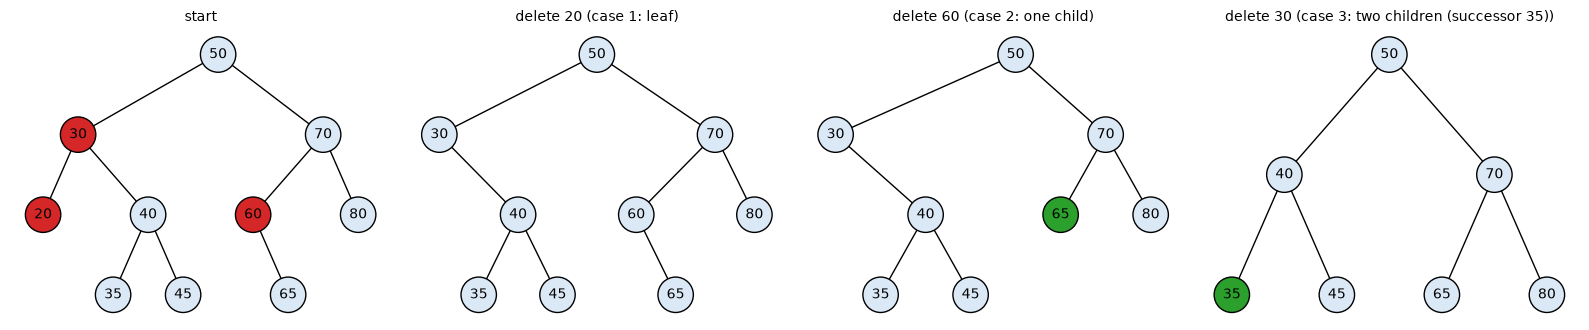

after the deletions: [35, 40, 45, 50, 65, 70, 80]


In [13]:
class BST:
    '''Binary search tree with distinct keys (stored in node.val).'''

    def __init__(self, keys=()):
        self.root = None
        self.size = 0
        for k in keys:
            self.insert(k)

    def search(self, key):                       # O(h)
        node = self.root
        while node is not None and node.val != key:
            node = node.left if key < node.val else node.right   # discard one side
        return node

    def insert(self, key):                       # O(h), iterative so deep trees are fine
        if self.root is None:
            self.root = TreeNode(key); self.size += 1; return True
        node = self.root
        while True:
            if key == node.val:
                return False                     # duplicate: ignore
            side = "left" if key < node.val else "right"
            child = getattr(node, side)
            if child is None:
                setattr(node, side, TreeNode(key)); self.size += 1; return True
            node = child

    def delete(self, key):                       # O(h)
        self.root, deleted = self._delete(self.root, key)
        self.size -= deleted
        return deleted

    def _delete(self, node, key):
        if node is None:
            return None, False                   # key not found
        if key < node.val:
            node.left, d = self._delete(node.left, key); return node, d
        if key > node.val:
            node.right, d = self._delete(node.right, key); return node, d
        if node.left is None:                    # case 1 (leaf) or case 2 (only a right child)
            return node.right, True
        if node.right is None:                   # case 2 (only a left child)
            return node.left, True
        succ = node.right                        # case 3: inorder successor = leftmost node of the right subtree
        while succ.left is not None:
            succ = succ.left
        node.val = succ.val                      # copy the successor's key here ...
        node.right, _ = self._delete(node.right, succ.val)   # ... and delete it below (case 1 or 2)
        return node, True

    def minimum(self):
        node = self.root
        while node.left: node = node.left
        return node.val

    def maximum(self):
        node = self.root
        while node.right: node = node.right
        return node.val

    def inorder(self):                           # iterative inorder generator: sorted keys
        stack, node = [], self.root
        while stack or node:
            while node:
                stack.append(node); node = node.left
            node = stack.pop()
            yield node.val
            node = node.right

    def kth_smallest(self, k):                   # O(h + k): stop the inorder walk after k keys
        for i, key in enumerate(self.inorder(), start=1):
            if i == k:
                return key
        raise IndexError("k is larger than the tree")

    def successor(self, key):
        '''Smallest key strictly greater than `key` (key need not be in the tree). O(h).'''
        node, best = self.root, None
        while node:
            if key < node.val:
                best = node.val                  # candidate; a smaller one may be on the left
                node = node.left
            else:
                node = node.right
        return best

    def height(self):                            # iterative (BFS) so it works on skewed trees
        if self.root is None: return -1
        h, queue = -1, deque([self.root])
        while queue:
            h += 1
            for _ in range(len(queue)):
                node = queue.popleft()
                if node.left: queue.append(node.left)
                if node.right: queue.append(node.right)
        return h


keys = [50, 30, 70, 20, 40, 60, 80, 35, 45, 65]
t = BST(keys)
print("inorder (sorted):", list(t.inorder()))
print("search(45) ->", t.search(45), "| search(99) ->", t.search(99), "| min", t.minimum(), "| max", t.maximum())
print("3rd smallest:", t.kth_smallest(3), "| successor(45):", t.successor(45), "| successor(80):", t.successor(80))

def copy_tree(n):
    return None if n is None else TreeNode(n.val, copy_tree(n.left), copy_tree(n.right))

snapshots = [("start", copy_tree(t.root), {})]
for key, case in [(20, "case 1: leaf"), (60, "case 2: one child"), (30, "case 3: two children (successor 35)")]:
    t.delete(key)
    snapshots.append((f"delete {key} ({case})", copy_tree(t.root), {}))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
highlight = [{20: "tab:red", 60: "tab:red", 30: "tab:red"}, {}, {65: "tab:green"}, {35: "tab:green"}]
for ax, (title, root_, _), col in zip(axes, snapshots, highlight):
    draw_tree(root_, ax, title, colors=col)
plt.tight_layout(); plt.show()
print("after the deletions:", list(t.inorder()))

**What just happened?** The inorder walk printed the keys sorted. `successor(45)` is 50 (the lowest ancestor for which 45 lies in the left subtree), and `successor(80)` is `None` (80 is the maximum). The pictures show the three delete cases: 20 (a leaf) simply disappears; 60 (one child) is replaced by its child 65 (green); 30 (two children) is overwritten by its inorder successor 35 (green), and the old 35 leaf is removed.

### 6.3 Validating a BST

⚠️ **Common mistake:** checking only that `left.val < node.val < right.val` for each node. The BST property is about **whole subtrees**. In the tree below every parent/child pair looks fine, but 60 sits in the left subtree of 50:

```
        50
       /  \
     30    80
    /  \
  10    60     <- 60 > 50, illegal in 50's left subtree
```

The correct check passes down an allowed range `(low, high)`: going left tightens `high`, going right tightens `low`. (Equivalently: the inorder traversal must be strictly increasing.)

In [14]:
def is_bst_naive(node):                          # WRONG: only looks at direct children
    if node is None:
        return True
    if node.left and node.left.val >= node.val: return False
    if node.right and node.right.val <= node.val: return False
    return is_bst_naive(node.left) and is_bst_naive(node.right)

def is_valid_bst(node, low=float("-inf"), high=float("inf")):
    if node is None:
        return True
    if not (low < node.val < high):              # must respect every ancestor's bound
        return False
    return is_valid_bst(node.left, low, node.val) and is_valid_bst(node.right, node.val, high)

tricky = from_level_order([50, 30, 80, 10, 60])
print("naive check:", is_bst_naive(tricky), "| correct check:", is_valid_bst(tricky))

rng = random.Random(9)
for _ in range(1000):
    n = rng.randint(0, 15)
    tree = random_binary_tree(n, rng, values=rng.sample(range(100), n))
    vals = inorder(tree)
    assert is_valid_bst(tree) == all(a < b for a, b in zip(vals, vals[1:]))
print("range-based validation == 'inorder is strictly increasing' on 1000 random trees")

naive check: True | correct check: False


range-based validation == 'inorder is strictly increasing' on 1000 random trees


In [15]:
# Randomised test of the whole BST class against a Python set + sorted list + bisect.
rng = random.Random(10)
for trial in range(30):
    tree, ref = BST(), set()
    for _ in range(600):
        key = rng.randint(0, 200)
        op = rng.random()
        if op < 0.5:
            assert tree.insert(key) == (key not in ref); ref.add(key)
        elif op < 0.8:
            assert tree.delete(key) == (key in ref); ref.discard(key)
        else:
            assert (tree.search(key) is not None) == (key in ref)
        if rng.random() < 0.1:                                   # occasionally run the expensive checks
            s = sorted(ref)
            assert list(tree.inorder()) == s and is_valid_bst(tree.root) and tree.size == len(s)
            if s:
                k = rng.randint(1, len(s)); assert tree.kth_smallest(k) == s[k - 1]
                q = rng.randint(-5, 205); i = bisect.bisect_right(s, q)
                assert tree.successor(q) == (s[i] if i < len(s) else None)
print("BST insert/delete/search/kth/successor agree with set + sorted list + bisect over 30 x 600 random operations")

BST insert/delete/search/kth/successor agree with set + sorted list + bisect over 30 x 600 random operations


### 6.4 The degenerate case: sorted input

If keys arrive **already sorted**, every new key is larger than all previous ones and goes to the far right: the BST becomes a linked list of height n − 1, and every operation becomes O(n). With keys in **random** order the expected height is O(log n) (more precisely, about 4.311 ln n for large n, and the *average* node depth is about 2 ln n ≈ 1.39 log₂ n). Let us measure it.

,sorted insert height,random insert height (avg of 5),log2(n),random height / log2(n)
n,,,,
100,99,12.0,6.6,1.81
250,249,16.2,8.0,2.03
500,499,19.0,9.0,2.12
1000,999,21.0,10.0,2.11
2000,1999,23.6,11.0,2.15
4000,3999,26.0,12.0,2.17


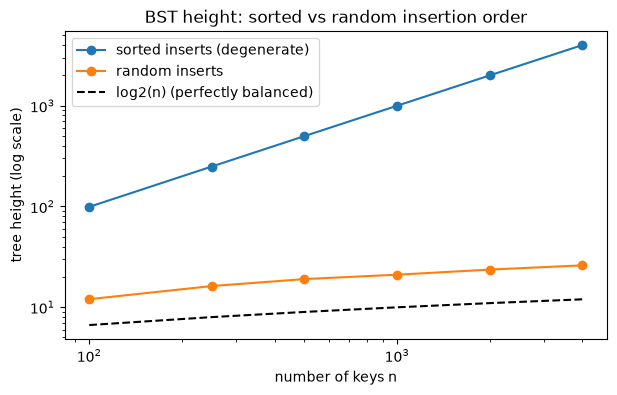

In [16]:
sizes = [100, 250, 500, 1000, 2000, 4000]
rows = []
for n in sizes:
    sorted_h = BST(range(n)).height()                                            # worst case
    rand_h = np.mean([BST(random.Random(s).sample(range(n), n)).height() for s in range(5)])   # average of 5 shuffles
    rows.append({"n": n, "sorted insert height": sorted_h, "random insert height (avg of 5)": rand_h,
                 "log2(n)": round(math.log2(n), 1), "random height / log2(n)": round(rand_h / math.log2(n), 2)})
heights = pd.DataFrame(rows).set_index("n")
display(heights)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, heights["sorted insert height"], "o-", label="sorted inserts (degenerate)")
ax.plot(sizes, heights["random insert height (avg of 5)"], "o-", label="random inserts")
ax.plot(sizes, [math.log2(n) for n in sizes], "k--", label="log2(n) (perfectly balanced)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("number of keys n"); ax.set_ylabel("tree height (log scale)")
ax.set_title("BST height: sorted vs random insertion order"); ax.legend(); plt.show()

**What just happened?** With sorted input the height is exactly n − 1 (3,999 for 4,000 keys): a linked list in disguise. With random input the height stays a small multiple of log₂ n (the last column of the table, roughly 1.8 to 2.2 here), growing very slowly. The gap is the difference between O(n) and O(log n) per operation, and real data is often sorted or nearly sorted (timestamps, auto-increment IDs). That is why production systems use **self-balancing** trees.

<a id="balanced"></a>
## 7. Balanced search trees

> **In plain English:** balanced trees rearrange themselves after changes so they never become a long, slow chain.

### 7.1 AVL trees (Adelson-Velsky and Landis, 1962)

An **AVL tree** is a BST in which every node's **balance factor** `bf = height(left) − height(right)` is −1, 0 or +1. After a normal BST insert we walk back up; at the first node where |bf| = 2 we fix it with one or two **rotations**. A rotation changes the shape locally but **keeps the inorder (sorted) order**.

```
Right rotation at y (fixes LL)            Left rotation at x (fixes RR)
        y                x                   x                    y
       / \              / \                 / \                  / \
      x   T3   ==>    T1   y               T1   y      ==>      x   T3
     / \                  / \                  / \             / \
   T1   T2              T2   T3              T2   T3          T1   T2
```

| Case | Where the new key went | bf at the unbalanced node | Fix |
|---|---|---|---|
| **LL** | left child's left subtree | +2, left child +1 | one **right** rotation |
| **RR** | right child's right subtree | −2, right child −1 | one **left** rotation |
| **LR** | left child's right subtree | +2, left child −1 | left-rotate the left child, then right-rotate the node |
| **RL** | right child's left subtree | −2, right child +1 | right-rotate the right child, then left-rotate the node |

Every node stores its height so balance factors are O(1) to compute; heights are updated bottom-up after each insertion and rotation.

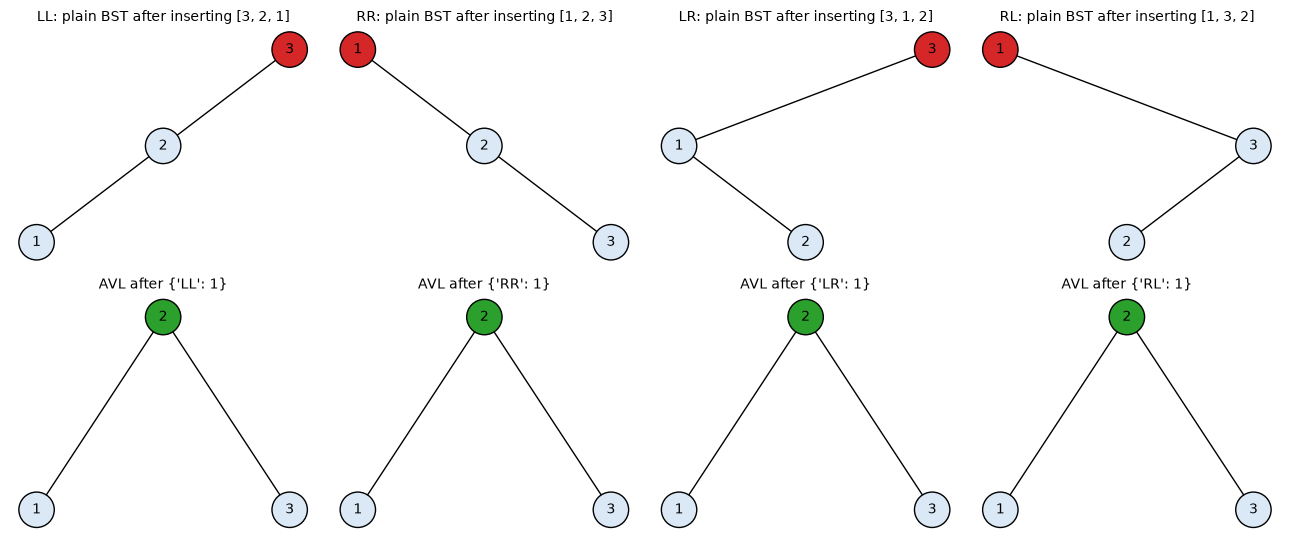

In [17]:
class AVLNode(TreeNode):
    def __init__(self, val):
        super().__init__(val)
        self.height = 0                          # a leaf has height 0 (edges convention)

def h(node):
    return node.height if node else -1

def update(node):
    node.height = 1 + max(h(node.left), h(node.right))

def balance_factor(node):
    return h(node.left) - h(node.right)

def rotate_right(y):
    x = y.left
    y.left = x.right                             # T2 changes parent: from x to y
    x.right = y                                  # y goes down to the right
    update(y); update(x)                         # y first: it is now below x
    return x                                     # x is the new root of this subtree

def rotate_left(x):
    y = x.right
    x.right = y.left
    y.left = x
    update(x); update(y)
    return y


class AVLTree:
    def __init__(self, keys=()):
        self.root, self.size = None, 0
        self.rotations = Counter()               # how many times each case happened
        for k in keys:
            self.insert(k)

    def insert(self, key):
        self.root = self._insert(self.root, key)

    def _insert(self, node, key):
        if node is None:                         # 1. ordinary BST insert ...
            self.size += 1
            return AVLNode(key)
        if key < node.val:
            node.left = self._insert(node.left, key)
        elif key > node.val:
            node.right = self._insert(node.right, key)
        else:
            return node                          # duplicate: nothing changes
        update(node)                             # 2. ... then fix heights on the way back up
        bf = balance_factor(node)
        if bf > 1 and key < node.left.val:       # LL
            self.rotations["LL"] += 1
            return rotate_right(node)
        if bf < -1 and key > node.right.val:     # RR
            self.rotations["RR"] += 1
            return rotate_left(node)
        if bf > 1 and key > node.left.val:       # LR
            self.rotations["LR"] += 1
            node.left = rotate_left(node.left)
            return rotate_right(node)
        if bf < -1 and key < node.right.val:     # RL
            self.rotations["RL"] += 1
            node.right = rotate_right(node.right)
            return rotate_left(node)
        return node


def check_avl(node):
    '''Assert the stored heights, the AVL balance condition and BST order. Returns the height.'''
    if node is None:
        return -1
    hl, hr = check_avl(node.left), check_avl(node.right)
    assert node.height == 1 + max(hl, hr), "stored height is wrong"
    assert abs(hl - hr) <= 1, "AVL balance violated"
    assert node.left is None or node.left.val < node.val
    assert node.right is None or node.right.val > node.val
    return node.height


cases = {"LL": [3, 2, 1], "RR": [1, 2, 3], "LR": [3, 1, 2], "RL": [1, 3, 2]}
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for col, (name, ks) in enumerate(cases.items()):
    draw_tree(BST(ks).root, axes[0, col], f"{name}: plain BST after inserting {ks}", colors={ks[0]: "tab:red"})
    avl = AVLTree(ks)
    draw_tree(avl.root, axes[1, col], f"AVL after {dict(avl.rotations)}", colors={avl.root.val: "tab:green"})
plt.tight_layout(); plt.show()

**What just happened?** Top row: inserting 3 keys in an unlucky order into a plain BST makes a chain of height 2, with the first key (red) unbalanced (bf = ±2). Bottom row: the AVL tree detects each of the four cases and rotates, always ending with the **middle key 2 at the root** (green) and height 1. LL and RR need one rotation; LR and RL need two (counted as one "case" in the title).

Now the real test: insert thousands of keys in random **and** sorted order, check the AVL invariants, and compare heights with the plain BST. The best possible guarantee is known exactly: the sparsest AVL tree of height h has N(h) = N(h−1) + N(h−2) + 1 nodes (a Fibonacci recurrence), which gives **h < 1.4405 log₂(n + 2)**. We check the exact Fibonacci bound.

In [18]:
def max_avl_height(n):
    '''Largest h such that the sparsest AVL tree of height h has <= n nodes.'''
    sparse = {0: 1, 1: 2}                        # N(0) = 1, N(1) = 2, N(h) = N(h-1) + N(h-2) + 1
    hh = 1
    while sparse[hh] <= n:
        hh += 1
        sparse[hh] = sparse[hh - 1] + sparse[hh - 2] + 1
    return hh - 1

rows = []
for n in [100, 1000, 4000]:
    for order in ["random", "sorted"]:
        ks = list(range(n)) if order == "sorted" else random.Random(n).sample(range(n), n)
        avl = AVLTree(ks)
        hgt = check_avl(avl.root)                # raises AssertionError if anything is wrong
        assert list(inorder(avl.root)) == sorted(ks) and avl.size == n
        assert hgt <= max_avl_height(n)
        rows.append({"n": n, "insert order": order, "AVL height": hgt, "plain BST height": BST(ks).height(),
                     "ceil(log2(n+1)) - 1": math.ceil(math.log2(n + 1)) - 1, "AVL bound": max_avl_height(n),
                     "rotations": dict(avl.rotations)})
display(pd.DataFrame(rows))

rng = random.Random(11)                          # many small random trees, invariants checked after EVERY insert
for _ in range(200):
    avl, ref = AVLTree(), set()
    for _ in range(rng.randint(1, 60)):
        k = rng.randint(0, 80); avl.insert(k); ref.add(k)
        check_avl(avl.root)
    assert inorder(avl.root) == sorted(ref)
print("AVL invariants hold after every insert in 200 random sequences")

,n,insert order,AVL height,plain BST height,ceil(log2(n+1)) - 1,AVL bound,rotations
0,100,random,7,13,6,8,"{'RR': 10, 'LR': 11, 'LL': 16, 'RL': 5}"
1,100,sorted,6,99,6,8,{'RR': 93}
2,1000,random,11,22,9,13,"{'LR': 101, 'LL': 124, 'RR': 117, 'RL': 110}"
3,1000,sorted,9,999,9,13,{'RR': 990}
4,4000,random,13,26,11,15,"{'RR': 477, 'LR': 480, 'LL': 451, 'RL': 394}"
5,4000,sorted,11,3999,11,15,{'RR': 3988}


AVL invariants hold after every insert in 200 random sequences


**What just happened?** Sorted input, which destroyed the plain BST (height n − 1), gives the AVL tree the **minimum possible height** ⌈log₂(n + 1)⌉ − 1 (sorted input produces only RR rotations and a nearly perfect tree). Random input gives a height just one or two levels above the minimum. Every AVL height is within the theoretical Fibonacci bound. Insert costs O(log n): one path down, at most one (single or double) rotation, and height updates on the way up.

Deletion in an AVL tree uses the same four rotations, but may need a rotation at **every** level on the way up (O(log n) rotations).

### 7.2 Red-black trees (conceptually)

A **red-black tree** is a BST where each node is coloured red or black, satisfying (CLRS):
1. Every node is red or black.
2. The root is black.
3. Every leaf (the `NIL` sentinel, i.e. empty child) is black.
4. A red node has **two black children** (no two reds in a row).
5. For every node, all paths down to descendant leaves contain the **same number of black nodes** (the node's **black-height**).

Properties 4 and 5 together mean the longest root-to-leaf path is at most twice the shortest, giving **height ≤ 2 log₂(n + 1)**. Insertion is fixed up with recolouring plus **at most 2 rotations**, deletion with **at most 3 rotations**.

**Why are they used?** AVL trees are more rigidly balanced (faster lookups), while red-black trees do fewer rotations per update (faster inserts/deletes). Red-black trees implement C++ `std::map`/`std::set` (in the common standard libraries), Java `TreeMap`/`TreeSet`, the overflow "tree bins" of Java's `HashMap`, and the Linux kernel's `rbtree` library (used, for example, by the CPU scheduler to order runnable tasks).

Below is a hand-made red-black tree and a checker for properties 2, 4 and 5.

good: ok=True, valid red-black tree
bad: ok=False, property 4: red node 8 has a red child 1


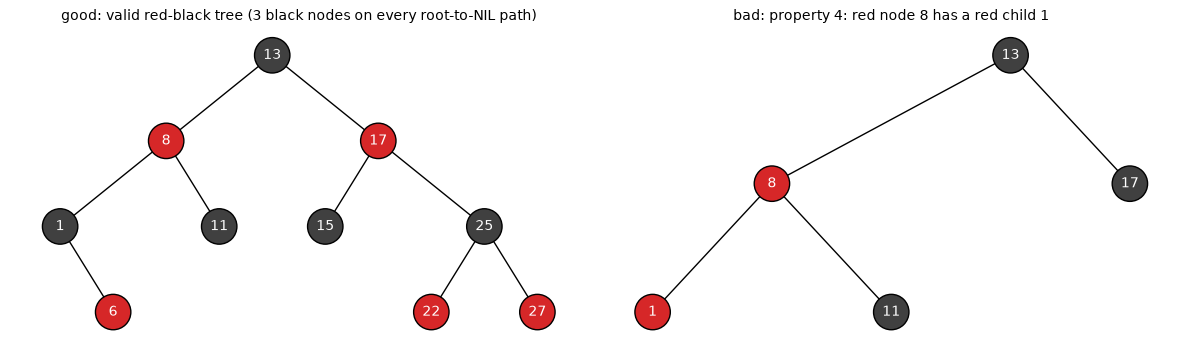

In [19]:
class RBNode(TreeNode):
    def __init__(self, val, color, left=None, right=None):
        super().__init__(val, left, right)
        self.color = color                       # "R" or "B"

def rb_check(root):
    '''Return (ok, message, black_height). NIL children count as black leaves.'''
    if root is not None and root.color != "B":
        return False, "property 2: root must be black", None
    def walk(node):
        if node is None:
            return 1                             # NIL leaf: black, black-height 1
        for child in (node.left, node.right):
            if node.color == "R" and child is not None and child.color == "R":
                raise ValueError(f"property 4: red node {node.val} has a red child {child.val}")
        bl, br = walk(node.left), walk(node.right)
        if bl != br:
            raise ValueError(f"property 5: different black counts below {node.val}")
        return bl + (node.color == "B")
    try:
        return True, "valid red-black tree", walk(root)
    except ValueError as e:
        return False, str(e), None

R, B = "R", "B"
good = RBNode(13, B, RBNode(8, R, RBNode(1, B, None, RBNode(6, R)), RBNode(11, B)),
                      RBNode(17, R, RBNode(15, B), RBNode(25, B, RBNode(22, R), RBNode(27, R))))
bad = RBNode(13, B, RBNode(8, R, RBNode(1, R), RBNode(11, B)), RBNode(17, B))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, tree_, name in [(axes[0], good, "good"), (axes[1], bad, "bad")]:
    ok, msg, bh = rb_check(tree_)
    cols = {}
    def collect(n):
        if n: cols[n.val] = "#d62728" if n.color == "R" else "#404040"; collect(n.left); collect(n.right)
    collect(tree_)
    draw_tree(tree_, ax, f"{name}: {msg}" + (f" ({bh} black nodes on every root-to-NIL path)" if ok else ""), colors=cols)
    for t in ax.texts: t.set_color("white")
    print(f"{name}: ok={ok}, {msg}")
plt.tight_layout(); plt.show()

**What just happened?** The left tree satisfies all five properties; every path from the root to a NIL leaf passes through the same number of black nodes (3, counting the root and the NIL leaf; CLRS's *black-height* of the root excludes the root itself, giving 2). The right tree has a red node (8) with a red child (1), violating property 4, and the checker says so (it also has unequal black counts, but the first violation found is reported).

| | AVL | Red-black |
|---|---|---|
| Balance rule | heights of siblings differ by ≤ 1 | colour rules 1 to 5 |
| Height bound | < 1.44 log₂(n + 2) | ≤ 2 log₂(n + 1) |
| Search | slightly faster (shallower) | slightly slower |
| Rotations per insert / delete | ≤ 2 / O(log n) | ≤ 2 / ≤ 3 |
| Typical use | read-heavy in-memory indexes | language libraries, OS kernels (update-heavy) |

### 7.3 B-trees and B+ trees (a mention)

Binary trees are a poor fit for **disks and SSDs**, where reading one block (4 to 16 KB) costs about the same as reading one byte. A **B-tree** of minimum degree t stores between t − 1 and 2t − 1 keys per node (except the root) and has up to 2t children, so each node fills a disk page and the tree is extremely **shallow**: height ≤ log_t((n + 1)/2). All leaves are at the same depth. A **B+ tree** keeps all records in the leaves and links the leaves together, which makes range scans (`WHERE age BETWEEN 20 AND 30`) a single sequential walk. B+ trees are the default index in almost every relational database (PostgreSQL, MySQL InnoDB, SQLite, ...).

The details (insert with node splits, deletes with merges, and hashing-based indexes) are in the DBMS notebook [Indexing: B-trees and hashing](../../13_Databases/00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb).

In [20]:
n = 1_000_000_000                                 # one billion keys
rows = []
for t in [2, 50, 100, 500]:
    rows.append({"minimum degree t": t, "max children per node": 2 * t,
                 "worst-case height  floor(log_t((n+1)/2))": math.floor(math.log((n + 1) / 2, t))})
rows.append({"minimum degree t": "binary (balanced)", "max children per node": 2,
             "worst-case height  floor(log_t((n+1)/2))": math.floor(math.log2(n))})
display(pd.DataFrame(rows))

,minimum degree t,max children per node,worst-case height floor(log_t((n+1)/2))
0,2,4,28
1,50,100,5
2,100,200,4
3,500,1000,3
4,binary (balanced),2,29


**What just happened?** For a billion keys, a balanced binary tree is about 29 levels deep, while a B-tree with t = 100 (up to 200 children per node) needs at most 4 levels below the root. With the top levels cached in memory, a lookup costs one or two disk reads.

<a id="heaps"></a>
## 8. Heaps and priority queues

> **In plain English:** a heap always keeps the smallest (or largest) item on top, which makes it the perfect priority queue.

### 8.1 Intuition and definition

A hospital emergency room does not treat patients in arrival order: it always treats the **most urgent** one next. We need a structure that can repeatedly hand out the minimum (or maximum) quickly while new items keep arriving.

A **binary min-heap** is a **complete** binary tree in which every node is **≤ its children** (the **heap property**; a **max-heap** uses ≥). Consequences: the minimum is always at the root; siblings are in no particular order (a heap is *not* sorted). Because the tree is complete, it is stored in an **array** with the index rules from section 3.1, and its height is ⌊log₂ n⌋.

- **push (sift-up):** append the new item at the end (the next free leaf), then swap it with its parent while it is smaller than the parent. O(log n).
- **pop (sift-down):** remove the root, move the **last** item to the root, then swap it with its **smaller child** while it is larger than that child. O(log n).
- **peek:** `a[0]`, O(1).

Hand trace: push 5, 3, 8, 1 into an empty min-heap.

| step | array before sift | sift | array after |
|---|---|---|---|
| push 5 | `[5]` | – | `[5]` |
| push 3 | `[5, 3]` | 3 < parent 5: swap | `[3, 5]` |
| push 8 | `[3, 5, 8]` | 8 > parent 3: stop | `[3, 5, 8]` |
| push 1 | `[3, 5, 8, 1]` | 1 < 5: swap; 1 < 3: swap | `[1, 3, 8, 5]` |
| pop → 1 | move last (5) to root: `[5, 3, 8]` | 5 > smaller child 3: swap | `[3, 5, 8]` |

,operation,array
0,push 5,[5]
1,push 3,"[3, 5]"
2,push 8,"[3, 5, 8]"
3,push 1,"[1, 3, 8, 5]"
4,pop -> 1,"[3, 5, 8]"


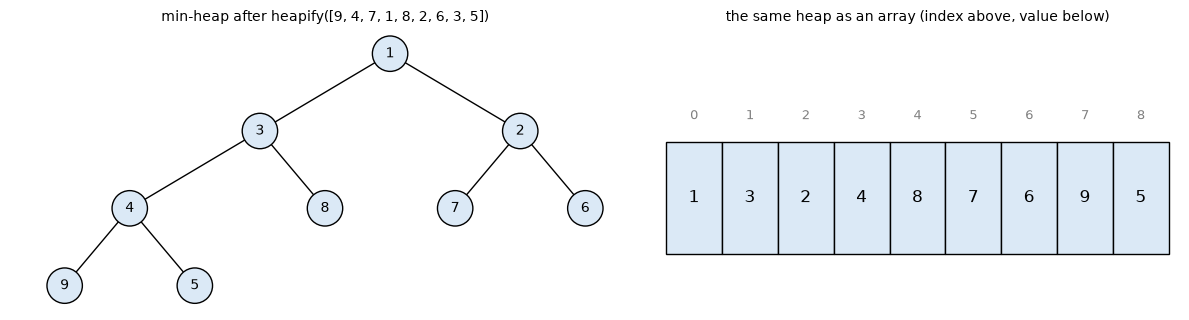

heap array: [1, 3, 2, 4, 8, 7, 6, 9, 5] | valid min-heap: True


MinHeap matches heapq on 20,000 random operations; heapify + repeated pop sorts 300 random lists


In [21]:
class MinHeap:
    '''Binary min-heap stored in a Python list.'''

    def __init__(self, items=None):
        self.a = list(items) if items else []
        self.swaps = 0                           # instrumentation for the heapify experiment
        if self.a:
            self._heapify()

    def __len__(self):
        return len(self.a)

    def peek(self):
        if not self.a:
            raise IndexError("peek from empty heap")
        return self.a[0]

    def push(self, x):                           # O(log n)
        self.a.append(x)                         # new leaf at the end keeps the tree complete
        self._sift_up(len(self.a) - 1)

    def pop(self):                               # O(log n)
        if not self.a:
            raise IndexError("pop from empty heap")
        last = self.a.pop()                      # remove the last leaf
        if not self.a:
            return last                          # it was the only item
        top, self.a[0] = self.a[0], last         # move it to the root ...
        self._sift_down(0)                       # ... and let it sink to its place
        return top

    def _swap(self, i, j):
        self.a[i], self.a[j] = self.a[j], self.a[i]
        self.swaps += 1

    def _sift_up(self, i):
        while i > 0:
            parent = (i - 1) // 2
            if self.a[i] < self.a[parent]:       # smaller than the parent: move up
                self._swap(i, parent)
                i = parent
            else:
                break

    def _sift_down(self, i):
        n = len(self.a)
        while True:
            left, right, smallest = 2 * i + 1, 2 * i + 2, i
            if left < n and self.a[left] < self.a[smallest]:
                smallest = left
            if right < n and self.a[right] < self.a[smallest]:
                smallest = right
            if smallest == i:                    # heap property restored
                return
            self._swap(i, smallest)              # swap with the SMALLER child
            i = smallest

    def _heapify(self):                          # O(n), bottom-up (explained below)
        for i in range(len(self.a) // 2 - 1, -1, -1):   # last internal node down to the root
            self._sift_down(i)


def is_min_heap(a):
    return all(a[(i - 1) // 2] <= a[i] for i in range(1, len(a)))


hp, rows = MinHeap(), []
for x in [5, 3, 8, 1]:
    hp.push(x); rows.append({"operation": f"push {x}", "array": list(hp.a)})
rows.append({"operation": f"pop -> {hp.pop()}", "array": list(hp.a)})
display(pd.DataFrame(rows))

demo = MinHeap([9, 4, 7, 1, 8, 2, 6, 3, 5])                  # heapify a list
heap_root = from_level_order(demo.a)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3), gridspec_kw={"width_ratios": [1.2, 1]})
draw_tree(heap_root, axes[0], "min-heap after heapify([9, 4, 7, 1, 8, 2, 6, 3, 5])")
axes[1].axis("off"); axes[1].set_title("the same heap as an array (index above, value below)", fontsize=10)
for i, v in enumerate(demo.a):
    axes[1].add_patch(plt.Rectangle((i, 0), 1, 1, facecolor="#dbe9f6", edgecolor="black"))
    axes[1].text(i + 0.5, 0.5, str(v), ha="center", va="center", fontsize=12)
    axes[1].text(i + 0.5, 1.2, str(i), ha="center", fontsize=9, color="gray")
axes[1].set_xlim(-0.2, len(demo.a) + 0.2); axes[1].set_ylim(-0.5, 2)
plt.tight_layout(); plt.show()
print("heap array:", demo.a, "| valid min-heap:", is_min_heap(demo.a))

rng = random.Random(12)                                       # randomised test against heapq
ours, ref = MinHeap(), []
for _ in range(20_000):
    if ref and rng.random() < 0.45:
        assert ours.pop() == heapq.heappop(ref)
    else:
        x = rng.randint(0, 1000); ours.push(x); heapq.heappush(ref, x)
    assert len(ours) == len(ref) and (not ref or ours.peek() == ref[0])
for _ in range(300):
    data = [rng.randint(0, 50) for _ in range(rng.randint(0, 100))]
    hh = MinHeap(data); assert is_min_heap(hh.a)
    assert [hh.pop() for _ in range(len(data))] == sorted(data)
print("MinHeap matches heapq on 20,000 random operations; heapify + repeated pop sorts 300 random lists")

**What just happened?** The trace table matches the hand trace (`[1, 3, 8, 5]` after the pushes, `[3, 5, 8]` after popping 1). The heapified list is a valid min-heap: every parent is ≤ its children, yet the array is not sorted. Our class behaves exactly like Python's `heapq` on 20,000 random operations.

### 8.2 Why heapify is O(n), not O(n log n)

Building a heap by n pushes costs O(n log n). **Bottom-up heapify** instead calls sift-down on every internal node, from the last one up to the root. The key observation: **most nodes are near the bottom**, where sift-down is cheap.

- A node at height k can sift down at most k levels.
- A heap of n nodes has at most ⌈n / 2^(k+1)⌉ nodes at height k (half the nodes are leaves with k = 0, a quarter have k = 1, ...).

Total work ≤ Σₖ (n / 2^(k+1)) · k = (n/2) · Σₖ k / 2^k ≤ (n/2) · 2 = **n**, because Σ_{k≥0} k / 2^k = 2. So heapify is **O(n)**.

Below we count swaps: bottom-up heapify versus n pushes, on the worst-case input for pushing (descending numbers, so every new item climbs to the root).

,heapify swaps / n,n pushes swaps / n,log2(n)
n,,,
63,0.905,4.095,5.977
511,0.982,7.018,8.997
4095,0.997,10.003,12.000
65535,1.000,14.000,16.000


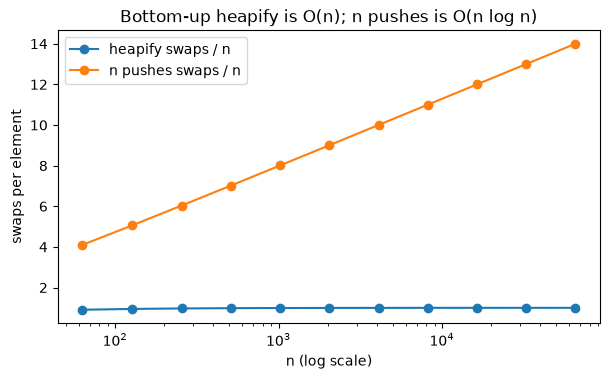

In [22]:
sizes = [2 ** k - 1 for k in range(6, 17)]                   # 63 ... 65535 (perfect trees)
rows = []
for n in sizes:
    data = list(range(n, 0, -1))                             # descending: worst case for push
    bottom_up = MinHeap(data).swaps
    pushes = MinHeap()
    for x in data:
        pushes.push(x)
    rows.append({"n": n, "heapify swaps / n": bottom_up / n, "n pushes swaps / n": pushes.swaps / n, "log2(n)": math.log2(n)})
exp = pd.DataFrame(rows).set_index("n")
display(exp.round(3).iloc[[0, 3, 6, 10]])
fig, ax = plt.subplots(figsize=(7, 3.8))
exp[["heapify swaps / n", "n pushes swaps / n"]].plot(ax=ax, marker="o", logx=True)
ax.set_xlabel("n (log scale)"); ax.set_ylabel("swaps per element"); ax.set_title("Bottom-up heapify is O(n); n pushes is O(n log n)")
plt.show()

**What just happened?** With bottom-up heapify the number of swaps per element stays **below 1** however large n gets (it approaches 1 for this worst-case input), i.e. total O(n). With repeated pushes the swaps per element grow like log₂ n (about 14 per element for n = 65,535), i.e. O(n log n) in total.

### 8.3 Heap sort

1. Build a **max-heap** in place (O(n)).
2. Repeat: swap the root (the maximum) with the last element of the heap, shrink the heap by one, and sift the new root down (O(log n) each).

Total **O(n log n) in the worst case**, **O(1) extra space** (in place). It is **not stable**: equal keys may change their relative order, as the demo shows.

In [23]:
def heap_sort(arr, key=lambda x: x):
    a = list(arr)
    n = len(a)
    def sift_down(i, size):                      # max-heap sift-down inside a[0:size]
        while True:
            l, r, largest = 2 * i + 1, 2 * i + 2, i
            if l < size and key(a[l]) > key(a[largest]): largest = l
            if r < size and key(a[r]) > key(a[largest]): largest = r
            if largest == i:
                return
            a[i], a[largest] = a[largest], a[i]
            i = largest
    for i in range(n // 2 - 1, -1, -1):          # 1. heapify into a max-heap
        sift_down(i, n)
    for end in range(n - 1, 0, -1):              # 2. move the max to the end, shrink, repair
        a[0], a[end] = a[end], a[0]
        sift_down(0, end)
    return a

print(heap_sort([5, 2, 9, 1, 5, 6, 0, 3]))
rng = random.Random(13)
for _ in range(500):
    data = [rng.randint(-100, 100) for _ in range(rng.randint(0, 200))]
    assert heap_sort(data) == sorted(data)
print("heap_sort == sorted() on 500 random lists")

cards = [(2, "a"), (1, "x"), (2, "b"), (1, "y"), (2, "c")]
print("sorted by number with heap sort:", heap_sort(cards, key=lambda c: c[0]))
print("sorted by number with sorted() :", sorted(cards, key=lambda c: c[0]), "<- stable (Timsort)")

[0, 1, 2, 3, 5, 5, 6, 9]


heap_sort == sorted() on 500 random lists
sorted by number with heap sort: [(1, 'x'), (1, 'y'), (2, 'b'), (2, 'c'), (2, 'a')]
sorted by number with sorted() : [(1, 'x'), (1, 'y'), (2, 'a'), (2, 'b'), (2, 'c')] <- stable (Timsort)


**What just happened?** Heap sort agrees with `sorted()` on 500 random lists. But when sorting the cards by number only, heap sort reordered the cards with number 2 (`b, c, a` instead of the original `a, b, c`; the 1s happened to stay in order), while Python's stable `sorted()` (Timsort) always keeps the original order of equal keys. In practice heap sort is used when a guaranteed O(n log n) worst case with O(1) extra memory matters (for example as the fallback inside **introsort**, used by many C++ standard libraries).

### 8.4 A priority-queue class (with priority updates)

A real priority queue often needs to **change** an item's priority (e.g. Dijkstra's algorithm, task schedulers). Finding an item inside a heap is O(n), so the standard trick (also recommended in the `heapq` documentation) is **lazy deletion**: mark the old entry as dead and push a new one; dead entries are skipped when they reach the top. A counter breaks ties in insertion order (FIFO among equal priorities) and prevents Python from ever comparing the items themselves.

In [24]:
class PriorityQueue:
    '''Min-priority queue with add-or-update and remove, built on our MinHeap.'''

    def __init__(self):
        self.heap = MinHeap()
        self.entries = {}                        # item -> its live entry [priority, count, item, alive]
        self.counter = itertools.count()         # tie-breaker: earlier insertions first

    def push(self, item, priority):              # add a new item or change its priority, O(log n)
        if item in self.entries:
            self.entries[item][3] = False        # lazily delete the old entry
        entry = [priority, next(self.counter), item, True]
        self.entries[item] = entry
        self.heap.push(entry)                    # lists compare by priority, then by count

    def remove(self, item):                      # O(1): just mark it dead
        self.entries.pop(item)[3] = False

    def pop(self):                               # amortised O(log n)
        while len(self.heap):
            priority, _, item, alive = self.heap.pop()
            if alive:
                del self.entries[item]
                return item, priority
        raise KeyError("pop from an empty priority queue")

    def __len__(self):
        return len(self.entries)


pq = PriorityQueue()
for task, pr in [("write report", 3), ("fix bug", 1), ("lunch", 2), ("email", 3)]:
    pq.push(task, pr)
pq.push("email", 0)                              # email becomes urgent
pq.remove("lunch")
print([pq.pop() for _ in range(len(pq))])

rng = random.Random(14)                          # randomised test against a brute-force dictionary
for _ in range(100):
    pq, ref, clock = PriorityQueue(), {}, 0
    for _ in range(300):
        op, item = rng.random(), rng.randint(0, 15)
        if op < 0.5:
            p = rng.randint(0, 9); pq.push(item, p); ref[item] = (p, clock); clock += 1
        elif op < 0.65 and item in ref:
            pq.remove(item); del ref[item]
        elif ref:
            best = min(ref, key=lambda k: ref[k])                # smallest (priority, insertion time)
            assert pq.pop() == (best, ref.pop(best)[0])
        assert len(pq) == len(ref)
print("PriorityQueue (push/update/remove/pop) matches a brute-force dict on 100 x 300 operations")

[('email', 0), ('fix bug', 1), ('write report', 3)]


PriorityQueue (push/update/remove/pop) matches a brute-force dict on 100 x 300 operations


**What just happened?** "email" was re-prioritised to 0 and "lunch" was removed, so the pops come out as `email (0)`, `fix bug (1)`, `write report (3)`. The stale "email (3)" and "lunch" entries are still inside the heap array, but they are skipped when popped.

### 8.5 Python's `heapq`

`heapq` provides functions that treat a plain list as a **min-heap**. For a max-heap, push negated keys (`-x`) or tuples `(-priority, item)`; Python 3.14 added dedicated max-heap functions (`heapq.heappush_max`, `heapq.heappop_max`, ...).

| Function | What it does | Time |
|---|---|---|
| `heapify(list)` | turn a list into a heap in place | O(n) |
| `heappush(h, x)` / `heappop(h)` | push / pop the smallest | O(log n) |
| `heappushpop(h, x)` | push then pop (faster than both) | O(log n) |
| `heapreplace(h, x)` | pop then push | O(log n) |
| `nlargest(k, it)` / `nsmallest(k, it)` | top-k | O(n log k) |
| `merge(*sorted_iterables)` | lazily merge sorted inputs | O(N log k) |

In [25]:
import sys
arr = [9, 4, 7, 1, 8, 2, 6, 3, 5]
heapq.heapify(arr)
print("heapify          :", arr, "(identical to our MinHeap:", arr == MinHeap([9, 4, 7, 1, 8, 2, 6, 3, 5]).a, ")")
print("nsmallest(3)     :", heapq.nsmallest(3, arr), "| nlargest(3):", heapq.nlargest(3, arr))
print("merge            :", list(heapq.merge([1, 4, 9], [2, 3, 10], [0, 5])))
maxh = []
for x in [5, 1, 8, 3]:
    heapq.heappush(maxh, -x)                     # max-heap by negation
print("max-heap pops    :", [-heapq.heappop(maxh) for _ in range(4)])
print("Python", sys.version.split()[0], "has heapq.heappush_max:", hasattr(heapq, "heappush_max"))

heapify          : [1, 3, 2, 4, 8, 7, 6, 9, 5] (identical to our MinHeap: True )
nsmallest(3)     : [1, 2, 3] | nlargest(3): [9, 8, 7]
merge            : [0, 1, 2, 3, 4, 5, 9, 10]
max-heap pops    : [8, 5, 3, 1]
Python 3.12.3 has heapq.heappush_max: False


**What just happened?** `heapq.heapify` produced exactly the same array as our `MinHeap` (both use bottom-up sift-down). Negating values turns the min-heap into a max-heap. The last line tells you whether your Python (3.14 or newer) has the dedicated `*_max` functions; the negation trick works on every version.

<a id="heap-problems"></a>
## 9. Heap problems

> **In plain English:** four favourite interview problems that become easy once you have a heap.

| Problem | Idea | Time | Space |
|---|---|---|---|
| k largest elements | keep a **min-heap of size k**; its root is the k-th largest so far | O(n log k) | O(k) |
| merge k sorted lists | heap holds the current head of each list | O(N log k) | O(k) |
| running median | **max-heap** for the lower half + **min-heap** for the upper half | O(log n) per item | O(n) |
| top-k frequent | count with a hash map, then a size-k heap | O(n + m log k) | O(m) |

(N = total elements, m = number of distinct values.)

In [26]:
def k_largest(nums, k):
    heap = []                                    # min-heap of the k largest seen so far
    for x in nums:
        if len(heap) < k:
            heapq.heappush(heap, x)
        elif x > heap[0]:                        # bigger than the smallest of the top k
            heapq.heapreplace(heap, x)           # pop the smallest, push x
    return sorted(heap, reverse=True)

def merge_k_sorted(lists):
    heap = [(lst[0], i, 0) for i, lst in enumerate(lists) if lst]   # (value, which list, index in it)
    heapq.heapify(heap)
    out = []
    while heap:
        value, i, j = heapq.heappop(heap)
        out.append(value)
        if j + 1 < len(lists[i]):
            heapq.heappush(heap, (lists[i][j + 1], i, j + 1))        # next element of the same list
    return out

class RunningMedian:
    def __init__(self):
        self.low = []                            # max-heap (negated) for the smaller half
        self.high = []                           # min-heap for the larger half
    def add(self, x):
        if not self.low or x <= -self.low[0]:
            heapq.heappush(self.low, -x)
        else:
            heapq.heappush(self.high, x)
        if len(self.low) > len(self.high) + 1:   # rebalance: sizes differ by at most one
            heapq.heappush(self.high, -heapq.heappop(self.low))
        elif len(self.high) > len(self.low):
            heapq.heappush(self.low, -heapq.heappop(self.high))
    def median(self):
        if len(self.low) > len(self.high):
            return -self.low[0]
        return (-self.low[0] + self.high[0]) / 2

def top_k_frequent(nums, k):
    counts = Counter(nums)                       # O(n)
    heap = []                                    # min-heap of the k "best" (freq, -value) pairs
    for value, freq in counts.items():
        item = (freq, -value)                    # ties: the smaller value counts as "more frequent"
        if len(heap) < k:
            heapq.heappush(heap, item)
        elif item > heap[0]:
            heapq.heapreplace(heap, item)
    return [-v for f, v in sorted(heap, reverse=True)]

print("3 largest of [3, 1, 5, 12, 2, 11, 7]:", k_largest([3, 1, 5, 12, 2, 11, 7], 3))
print("merge [[1,4,7],[2,5,8],[0,3,6,9]]:", merge_k_sorted([[1, 4, 7], [2, 5, 8], [0, 3, 6, 9]]))
rm = RunningMedian(); meds = []
for x in [5, 15, 1, 3, 8]:
    rm.add(x); meds.append(rm.median())
print("running medians of 5, 15, 1, 3, 8:", meds)
print("top-2 frequent of [1,1,1,2,2,3]:", top_k_frequent([1, 1, 1, 2, 2, 3], 2))

rng = random.Random(15)
for _ in range(300):
    nums = [rng.randint(-50, 50) for _ in range(rng.randint(1, 200))]
    k = rng.randint(1, len(nums))
    assert k_largest(nums, k) == sorted(nums, reverse=True)[:k] == heapq.nlargest(k, nums)
    lists = [sorted(rng.randint(0, 99) for _ in range(rng.randint(0, 15))) for _ in range(rng.randint(0, 8))]
    assert merge_k_sorted(lists) == sorted(sum(lists, [])) == list(heapq.merge(*lists))
    m = len(set(nums)); kk = rng.randint(1, m)
    expected = [v for v, f in sorted(Counter(nums).items(), key=lambda vf: (-vf[1], vf[0]))[:kk]]
    assert top_k_frequent(nums, kk) == expected
stream = [rng.gauss(0, 1) for _ in range(1000)]
rm, ours = RunningMedian(), []
for x in stream:
    rm.add(x); ours.append(rm.median())
assert all(math.isclose(ours[i], statistics.median(stream[:i + 1])) for i in range(len(stream)))
print("k-largest, merge-k, top-k-frequent and running median all match brute force / heapq / statistics.median")

3 largest of [3, 1, 5, 12, 2, 11, 7]: [12, 11, 7]
merge [[1,4,7],[2,5,8],[0,3,6,9]]: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
running medians of 5, 15, 1, 3, 8: [5, 10.0, 5, 4.0, 5]
top-2 frequent of [1,1,1,2,2,3]: [1, 2]


k-largest, merge-k, top-k-frequent and running median all match brute force / heapq / statistics.median


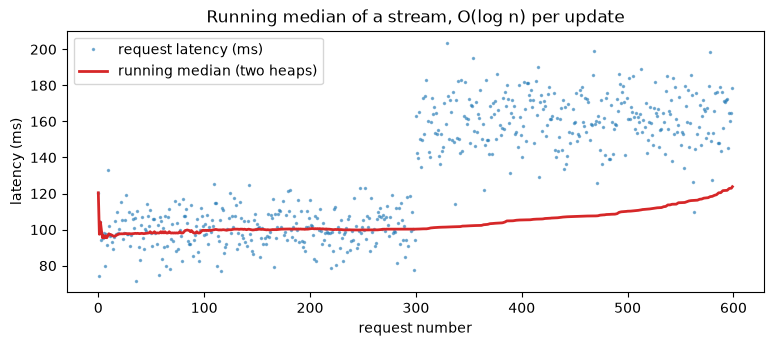

In [27]:
rng_np = np.random.default_rng(3)
latencies = np.concatenate([rng_np.normal(100, 10, 300), rng_np.normal(160, 15, 300)])   # a shift halfway
rm, med = RunningMedian(), []
for x in latencies:
    rm.add(float(x)); med.append(rm.median())
plt.figure(figsize=(9, 3.4))
plt.plot(latencies, ".", ms=3, alpha=0.5, label="request latency (ms)")
plt.plot(med, lw=2, color="tab:red", label="running median (two heaps)")
plt.xlabel("request number"); plt.ylabel("latency (ms)"); plt.title("Running median of a stream, O(log n) per update")
plt.legend(); plt.show()

**What just happened?** The three largest are `[12, 11, 7]`; the k-way merge interleaves the lists correctly; the running medians of 5, 15, 1, 3, 8 are 5, 10, 5, 4, 5; and the top-2 frequent values of `[1, 1, 1, 2, 2, 3]` are `[1, 2]`. The plot shows the running median of a simulated latency stream: it reacts to the shift halfway through but, unlike the mean, is barely moved by individual outliers. All four solutions matched brute-force references on hundreds of random inputs (and the running median matched `statistics.median` on every one of the 1,000 prefixes).

⚠️ **Common mistake:** for "k largest" people often build a **max-heap of all n items** and pop k times: O(n + k log n) time but O(n) memory. The size-k **min-heap** uses only O(k) memory and works on a stream that does not fit in memory.

<a id="summary"></a>
## 10. Complexity summary

> **In plain English:** one table with the speed of every operation in this notebook, for quick revision.

| Structure / operation | Average | Worst | Space |
|---|---|---|---|
| Traversals (any order) | O(n) | O(n) | O(h) stack or O(w) queue |
| BST search / insert / delete | O(log n) | **O(n)** (skewed) | O(n) |
| BST k-th smallest (inorder walk) | O(h + k) | O(n) | O(h) |
| AVL search / insert / delete | O(log n) | O(log n) | O(n) |
| Red-black search / insert / delete | O(log n) | O(log n) | O(n) |
| B-tree search (disk reads) | O(log_t n) | O(log_t n) | O(n) |
| Heap peek | O(1) | O(1) | |
| Heap push / pop | O(log n) | O(log n) | O(n) |
| Heapify (bottom-up) | O(n) | O(n) | O(1) extra |
| Heap sort | O(n log n) | O(n log n) | O(1) extra, not stable |
| Search for an arbitrary key in a heap | O(n) | O(n) | |

<a id="modern-ai"></a>
## 11. 🔗 How this connects to modern AI

> **In plain English:** trees and heaps power decision-tree models, top-k retrieval for LLMs, beam search and the databases behind AI products.

- **Decision trees and boosted ensembles** (scikit-learn, XGBoost, LightGBM) *are* binary trees: each internal node is a test such as `age < 30`, each leaf a prediction, and prediction is a root-to-leaf walk (O(depth)). See [decision trees](../../03_Machine_Learning/01_supervised/03_decision_trees.ipynb) and [ensemble methods](../../03_Machine_Learning/01_supervised/04_ensemble_methods.ipynb).
- **Top-k retrieval in RAG and vector search** keeps the k most similar documents with a size-k heap, exactly the `k_largest` pattern. See [RAG fundamentals](../../08_LLM/02_rag/01_rag_fundamentals.ipynb) and [vector databases](../../13_Databases/03_vector_db/01_vector_databases.ipynb).
- **LLM decoding:** top-k sampling and **beam search** repeatedly select the k best candidates (a heap or partial sort), and beam search explores a tree of partial sentences. See [language models and generation](../../07_NLP/05_language_models_and_generation.ipynb).
- **Nearest-neighbour search** in k-NN uses space-partitioning trees (k-d trees, ball trees) that generalise BSTs to many dimensions. See [k-NN](../../03_Machine_Learning/01_supervised/07_knn.ipynb).
- **B+ trees behind data platforms:** the relational databases and feature stores that serve training data index their tables with B+ trees (see the DBMS indexing notebook linked in section 7.3).
- **Tree search in reasoning:** game-tree search (minimax, Monte Carlo tree search in AlphaGo/AlphaZero) and "tree of thoughts" style LLM reasoning explore trees of states, typically with a priority queue of the most promising nodes. See [reasoning models](../../08_LLM/18_reasoning_models.ipynb).

levels: [[30], [20, 40], [10, 25, 50]] | rotations: {'RR': 2, 'RL': 1}


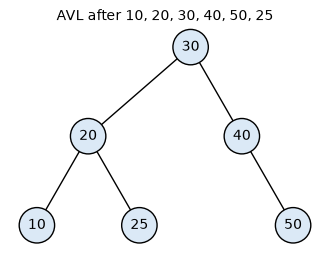

In [28]:
# Used by practice problem 2 below: the AVL tree for 10, 20, 30, 40, 50, 25
avl = AVLTree([10, 20, 30, 40, 50, 25])
print("levels:", levels(avl.root), "| rotations:", dict(avl.rotations))
fig, ax = plt.subplots(figsize=(4, 2.8)); draw_tree(avl.root, ax, "AVL after 10, 20, 30, 40, 50, 25"); plt.show()

<a id="recap"></a>
## 12. Recap

> **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- A **tree** has n nodes and n − 1 edges; **depth** counts edges from the root, **height** counts edges down to the deepest leaf (state your convention!).
- Binary trees can be **full** (0 or 2 children), **complete** (filled level by level from the left, so they fit in an array with children at 2i + 1 and 2i + 2) or **perfect** (both, with 2^(h+1) − 1 nodes).
- **Traversals:** preorder, inorder, postorder (DFS with a stack, O(h) space) and level order (BFS with a queue). Inorder of a BST is sorted.
- Most tree problems are "solve the subtrees, combine at the node": height, diameter, LCA, path sum, symmetry; views use BFS; serialisation uses preorder with null markers.
- A **BST** gives O(h) search/insert/delete (three delete cases); sorted input makes it degenerate (h = n − 1), which we measured.
- **AVL** trees keep |balance factor| ≤ 1 with LL/RR/LR/RL rotations (h < 1.44 log₂ n); **red-black** trees use colour rules (h ≤ 2 log₂(n + 1), fewer rotations); **B/B+ trees** are wide and shallow for disks and databases.
- A **binary heap** is a complete tree in an array with the heap property: O(1) peek, O(log n) push/pop, **O(n) heapify**, O(n log n) heap sort, and it powers **priority queues** and top-k/median/merge problems.

## Practice problems

**1. (Easy, conceptual)** (a) What is the minimum and maximum number of nodes in a binary tree of height 4 (edges convention)? (b) What is the height of a complete binary tree with 1,000 nodes? (c) In a min-heap stored as an array, where is the parent of the element at index 37, and where can the **maximum** element be?

<details><summary>Show solution</summary>

(a) Minimum **5** (a chain), maximum 2⁵ − 1 = **31** (perfect tree). (b) ⌊log₂ 1000⌋ = **9**. (c) Parent index ⌊(37 − 1)/2⌋ = **18**. The maximum of a min-heap must be a **leaf**, i.e. somewhere in the last ⌈n/2⌉ positions (indices ⌊n/2⌋ to n − 1); you cannot know which one without scanning them.
</details>

**2. (Medium, conceptual)** Insert 10, 20, 30, 40, 50, 25 (in this order) into an empty AVL tree. Which rotations happen and what is the final tree?

<details><summary>Show solution</summary>

- 10, 20, 30: node 10 gets bf = −2 with the new key in the right-right subtree → **RR**: left rotation, root becomes 20 (children 10, 30).
- 40, then 50: node 30 gets bf = −2 (RR) → left rotation at 30; 40 becomes the right child of 20 with children 30 and 50.
- 25: goes to 30's left; now the root 20 has bf = −2 and 25 went into the right child's (40's) **left** subtree → **RL**: right-rotate 40, then left-rotate 20. Final tree: root **30**, left child 20 (children 10, 25), right child 40 (right child 50).

The code cell just above this recap prints `levels: [[30], [20, 40], [10, 25, 50]]` and `rotations: {'RR': 2, 'RL': 1}`, confirming the answer.
</details>

**3. (Easy, coding)** Invert (mirror) a binary tree: swap the left and right children of every node.

<details><summary>Show solution</summary>

```python
def invert(node):
    if node is None:
        return None
    node.left, node.right = invert(node.right), invert(node.left)   # swap, after inverting both sides
    return node
```
O(n) time, O(h) space. (Tested against a mirror-copy on 300 random trees.)
</details>

**4. (Medium, coding + conceptual)** Rebuild a binary tree (distinct values) from its preorder and inorder traversals in O(n). By hand: preorder `[3, 9, 20, 15, 7]`, inorder `[9, 3, 15, 20, 7]`. What is the postorder?

<details><summary>Show solution</summary>

The first preorder value is the root; its position in the inorder list splits the left and right subtrees. A dictionary of inorder positions makes each split O(1).
```python
def build_from_pre_in(preorder, inorder):
    index = {v: i for i, v in enumerate(inorder)}     # value -> position in inorder, O(1) lookups
    pre_iter = iter(preorder)
    def build(lo, hi):                                 # build the subtree whose inorder slice is [lo, hi)
        if lo >= hi:
            return None
        root_val = next(pre_iter)                      # preorder gives the root first
        mid = index[root_val]
        node = TreeNode(root_val)
        node.left = build(lo, mid)                     # everything left of the root in inorder
        node.right = build(mid + 1, hi)                # everything right of it
        return node
    return build(0, len(inorder))
```
By hand: root 3, left subtree {9}, right subtree {15, 20, 7} with root 20 (children 15 and 7). Postorder: **9, 15, 7, 20, 3**. (Code tested on 500 random trees.)
</details>

**5. (Medium, coding)** Convert a sorted array into a height-balanced BST. What height do you get for n keys?

<details><summary>Show solution</summary>

Make the middle element the root and recurse on both halves.
```python
def sorted_array_to_bst(arr, lo=0, hi=None):
    if hi is None:
        hi = len(arr)
    if lo >= hi:
        return None
    mid = (lo + hi) // 2                               # middle element becomes the root
    return TreeNode(arr[mid], sorted_array_to_bst(arr, lo, mid), sorted_array_to_bst(arr, mid + 1, hi))
```
The height is ⌈log₂(n + 1)⌉ − 1, the minimum possible (tested for n = 0 to 199; inorder equals the input and every node is balanced).
</details>

**6. (Medium, coding)** Design a class `KthLargest(k, nums)` with `add(x)` that returns the k-th largest element of the stream so far, in O(log k) per call.

<details><summary>Show solution</summary>

```python
import heapq

class KthLargest:
    def __init__(self, k, nums=()):
        self.k, self.heap = k, []                      # min-heap holding the k largest so far
        for x in nums:
            self.add(x)
    def add(self, x):
        if len(self.heap) < self.k:
            heapq.heappush(self.heap, x)
        elif x > self.heap[0]:
            heapq.heapreplace(self.heap, x)
        return self.heap[0] if len(self.heap) == self.k else None   # the k-th largest
```
For k = 3 and initial `[4, 5, 8, 2]`, adding 3, 5, 10, 9, 4 returns 4, 5, 5, 8, 8. (Tested against sorting on 200 random streams.)
</details>

**7. (Hard, coding)** A BST was serialised as its **preorder** only (no null markers). Rebuild it in O(n).

<details><summary>Show solution</summary>

In a BST the key ranges tell us where each subtree ends: pass down the allowed range `(low, high)`; the next preorder key belongs to this subtree only if it lies in the range.
```python
def bst_from_preorder(preorder):
    it, nxt = iter(preorder), [None]
    def advance():
        nxt[0] = next(it, None)
    advance()
    def build(low, high):                              # keys allowed in this subtree: (low, high)
        v = nxt[0]
        if v is None or not (low < v < high):
            return None
        advance()
        node = TreeNode(v)
        node.left = build(low, v)
        node.right = build(v, high)
        return node
    return build(float("-inf"), float("inf"))
```
Each key is consumed once: O(n). (Round trip tested on 500 random BSTs.) This is why BSTs need no null markers but general binary trees do.
</details>

## Further reading

- CLRS, *Introduction to Algorithms*, 4th ed. (2022): Ch. 6 "Heapsort" (heaps and priority queues), Ch. 12 "Binary Search Trees", Ch. 13 "Red-Black Trees" (AVL trees appear as Problem 13-3), Ch. 18 "B-Trees".
- Sedgewick and Wayne, *Algorithms*, 4th ed.: §2.4 "Priority Queues", §3.2 "Binary Search Trees", §3.3 "Balanced Search Trees" (2-3 and left-leaning red-black trees). Free companion site: algs4.cs.princeton.edu.
- Goodrich, Tamassia, Goldwasser, *Data Structures and Algorithms in Python*: Ch. 8 "Trees", Ch. 9 "Priority Queues", Ch. 11 "Search Trees".
- Python documentation for the `heapq` module (includes the priority-queue implementation notes used in section 8.4).
- VisuAlgo (visualgo.net): animated BST, AVL and binary-heap operations.

## Next notebook

➡️ [07 · Graphs](07_graphs.ipynb): trees are special graphs; next we drop the "one parent" rule and study BFS, DFS, shortest paths, spanning trees and more.